# Praktikum Machine Learning: Klasifikasi Pay Band

**Nama:** Benedictus Ryu Gunawan

**NRP:** 5054251001

Template Kaggle Competition Praktikum Machine Learning (materi Klasifikasi).

**Link Chat**:
- https://chat.deepseek.com/share/tl0ldp0d8uc265ufnv
- https://chat.deepseek.com/share/m8q0elg95249smt4cx

## Setup

In [55]:
# Import Library
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

from pathlib import Path

ROOT_DIR = Path(os.getcwd()).parent
DATA_DIR = ROOT_DIR / "data"
TARGET = "pay_band"
SEED = 3407

## Load Data

In [56]:
# Sesuaikan path dengan lokasi file kalian (Kaggle: /kaggle/input/<nama-kompetisi>/...)
df_train = pd.read_csv(DATA_DIR / 'train.csv', na_values=["", " ", "NA", "N/A", "na", "n/a", "null", "NULL", "?", "-", "unknown", "Unknown", "UNKNOWN"])
df_test = pd.read_csv(DATA_DIR / 'test.csv', na_values=["", " ", "NA", "N/A", "na", "n/a", "null", "NULL", "?", "-", "unknown", "Unknown", "UNKNOWN"])

df_train.index = df_train["employee_id"]
df_test.index = df_test["employee_id"]
df_train.drop(columns=["employee_id","record_hash"], inplace=True)
df_test.drop(columns=["employee_id", "record_hash"], inplace=True)

print(df_train.shape, df_test.shape)
df_train.head()

(60430, 19) (29070, 18)


,source_dataset,import_batch,age,gender,ethnicity,education_level,years_experience,tenure_years,department,job_title,country,remote_status,performance_rating,performance_review_score,hire_date,currency,salary_raw,notes,pay_band
employee_id,,,,,,,,,,,,,,,,,,,
EMP-194754,hris_export_2023,24,NaN,NaN,NaN,bachelor's degree,NaN,6.0,Engineering,STAFF ENG.,PH,Hybrid,exceeds,3.1,04-30-2020,PHP,"191,210 per month",NaN,Band 2
EMP-109967,hris_export_2023,22,0.0,female,White,Associate Degree,24.0,0.0,IT,IT SUPPORT SPECIALIST,Brazil,On site,Meets Expectations,4.1,02 Apr 2026,BRL,"BRL 250,722",NaN,Band 2
EMP-128419,hris_export_2023,8,33.0,FEMALE,NaN,PhD,12.0,1.0,Legal,Paralegal,United Kingdom,Remote,Meets Expectations,2.1,23 Dec 2024,NaN,"28,276.28",NaN,Band 1
EMP-108690,hris_export_2023,39,NaN,Woman,Asian,PhD,20.0,4.0,Legal,paralegal,Brazil,On-site,Meets Expectations,4.1,2022-07-20,BRL,18315 monthly,NaN,Band 1
EMP-169742,acquired_company_legacy,22,39.0,Other,White,bachelor's degree,-1.0,4.0,Data Science Department,ML Enginer,USA,Hybrid,NaN,3.5,"March 31, 2022",USD,"20.855,27 USD",NaN,Band 1


In [57]:
display(df_train.info())
display(df_test.info())

<class 'pandas.core.frame.DataFrame'>
Index: 60430 entries, EMP-194754 to EMP-179655
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   source_dataset            60430 non-null  object 
 1   import_batch              60430 non-null  int64  
 2   age                       40919 non-null  float64
 3   gender                    58629 non-null  object 
 4   ethnicity                 45257 non-null  object 
 5   education_level           57487 non-null  object 
 6   years_experience          38853 non-null  float64
 7   tenure_years              59842 non-null  float64
 8   department                60430 non-null  object 
 9   job_title                 59229 non-null  object 
 10  country                   60430 non-null  object 
 11  remote_status             53760 non-null  object 
 12  performance_rating        57377 non-null  object 
 13  performance_review_score  50784 non-null  float64
 1

None

<class 'pandas.core.frame.DataFrame'>
Index: 29070 entries, EMP-196598 to EMP-147506
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   source_dataset            29070 non-null  object 
 1   import_batch              29070 non-null  int64  
 2   age                       28208 non-null  object 
 3   gender                    28196 non-null  object 
 4   ethnicity                 21765 non-null  object 
 5   education_level           27643 non-null  object 
 6   years_experience          28777 non-null  object 
 7   tenure_years              28758 non-null  float64
 8   department                29070 non-null  object 
 9   job_title                 28463 non-null  object 
 10  country                   29070 non-null  object 
 11  remote_status             25773 non-null  object 
 12  performance_rating        27653 non-null  object 
 13  performance_review_score  24652 non-null  float64
 1

None

In [58]:
df_train['hire_date'] = pd.to_datetime(df_train['hire_date'], format="mixed")
df_test['hire_date'] = pd.to_datetime(df_test['hire_date'], format="mixed")

In [59]:
df_train['hire_date'].isnull().sum(), df_test['hire_date'].isnull().sum()

(np.int64(0), np.int64(22195))

In [60]:
cat_cols = df_test.select_dtypes(include=['object']).columns.tolist()
cat_cols

['source_dataset',
 'age',
 'gender',
 'ethnicity',
 'education_level',
 'years_experience',
 'department',
 'job_title',
 'country',
 'remote_status',
 'performance_rating',
 'currency',
 'salary_raw',
 'notes']

## Handle (Year) -> For EDA 

I know it's weird tbh

In [61]:
# Looks like that, age on test have different object type, we need to convert it to numeric type
import re

pattern = r'\d+'
regex = re.compile(pattern)
matches = df_test['age'].apply(lambda x: regex.findall(str(x)))

# Take the first match and convert it to numeric, if there is no match, return NaN
df_test['age'] = matches.apply(lambda x: int(x[0]) if x else np.nan)

# For the number > 1900, we can convert it to 2026-year
df_test['age'] = df_test['age'].apply(lambda x: 2026 - x if x > 1900 else x)
df_test['age'] = pd.to_numeric(df_test['age'], errors='coerce')
df_test['age']

employee_id
EMP-196598     27.0
EMP-156920     37.0
EMP-161973    999.0
EMP-195108     31.0
EMP-111307     45.0
              ...  
EMP-184759     49.0
EMP-184544      NaN
EMP-131946     37.0
EMP-152621     29.0
EMP-147506    150.0
Name: age, Length: 29070, dtype: float64

## Handle (Years Experience) -> For EDA Purpose

In [62]:
# We must to split the years of experience in test_set. So, 19 months will be [19, months]
df_test['years_experience'] = df_test['years_experience'].apply(lambda x: str(x).split())
# if the second element is 'months', we will convert it to years by dividing it by 12

df_test['years_experience'] = df_test['years_experience'].apply(lambda x: float(x[0]) / 12 if len(x) > 1 and x[1] == 'months' else float(x[0]))

print(df_test['years_experience'])

employee_id
EMP-196598    -1.0
EMP-156920    14.0
EMP-161973     0.0
EMP-195108     9.0
EMP-111307    -1.0
              ... 
EMP-184759    28.0
EMP-184544     6.0
EMP-131946    -1.0
EMP-152621     6.0
EMP-147506     6.0
Name: years_experience, Length: 29070, dtype: float64


## Exploratory Data Analysis

Lengkapi bagian ini sesuai dengan **EDA** yang kalian lakukan.

In [63]:
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns

### Missing Analysis

In [64]:
train_missing = df_train.isnull().sum()
test_missing = df_test.isnull().sum()
train_missing = train_missing[train_missing > 0]
test_missing = test_missing[test_missing > 0]

train_missing_percent = (train_missing / len(df_train)) * 100
test_missing_percent = (test_missing / len(df_test)) * 100

train_missing_df = pd.DataFrame({'column_name': train_missing.index, 'missing_count': train_missing.values, 'missing_percent': train_missing_percent.values}).sort_values(by='missing_count', ascending=False)
test_missing_df = pd.DataFrame({'column_name': test_missing.index, 'missing_count': test_missing.values, 'missing_percent': test_missing_percent.values}).sort_values(by='missing_count', ascending=False)

display(train_missing_df)
display(test_missing_df)

,column_name,missing_count,missing_percent
11,notes,54297,89.851067
4,years_experience,21577,35.705775
0,age,19511,32.286944
2,ethnicity,15173,25.108390
9,performance_review_score,9646,15.962270
10,currency,7325,12.121463
7,remote_status,6670,11.037564
8,performance_rating,3053,5.052126
3,education_level,2943,4.870098
1,gender,1801,2.980308


,column_name,missing_count,missing_percent
12,notes,26159,89.986240
10,hire_date,22195,76.350189
2,ethnicity,7305,25.128999
9,performance_review_score,4418,15.197798
11,currency,3533,12.153423
7,remote_status,3297,11.341589
3,education_level,1427,4.908841
8,performance_rating,1417,4.874441
1,gender,874,3.006536
0,age,862,2.965256


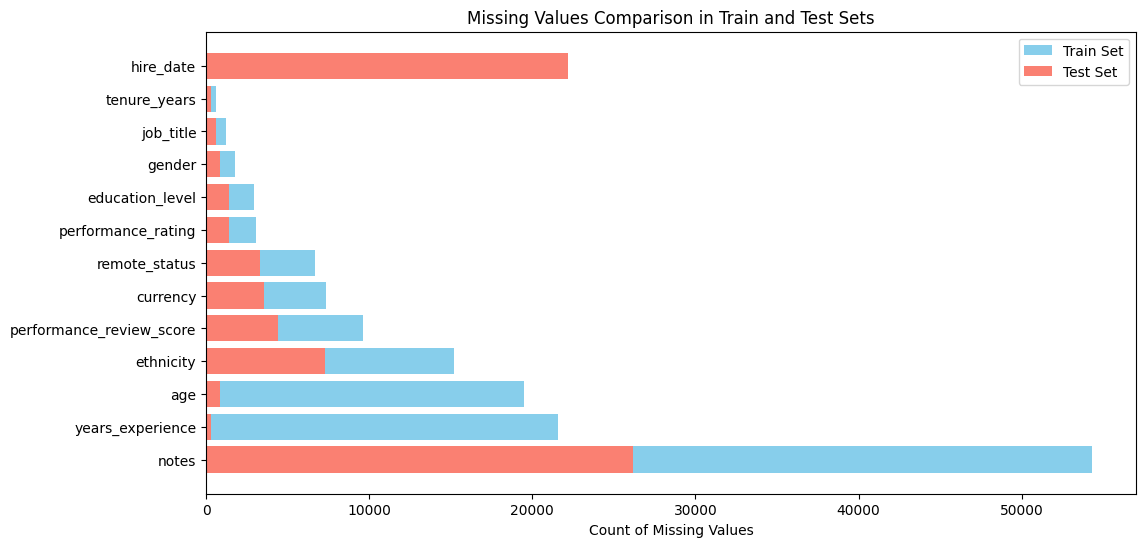

In [65]:
# Plot Missing Values
plt.figure(figsize=(12, 6))
plt.barh(train_missing_df['column_name'], train_missing_df['missing_count'], color='skyblue')
plt.xlabel('Count of Missing Values')
plt.barh(test_missing_df['column_name'], test_missing_df['missing_count'], color='salmon')
plt.title('Missing Values Comparison in Train and Test Sets')
plt.legend(['Train Set', 'Test Set'])




looks like there's a distribution shift here. `Hire Date` have high missing on test and no missing on train

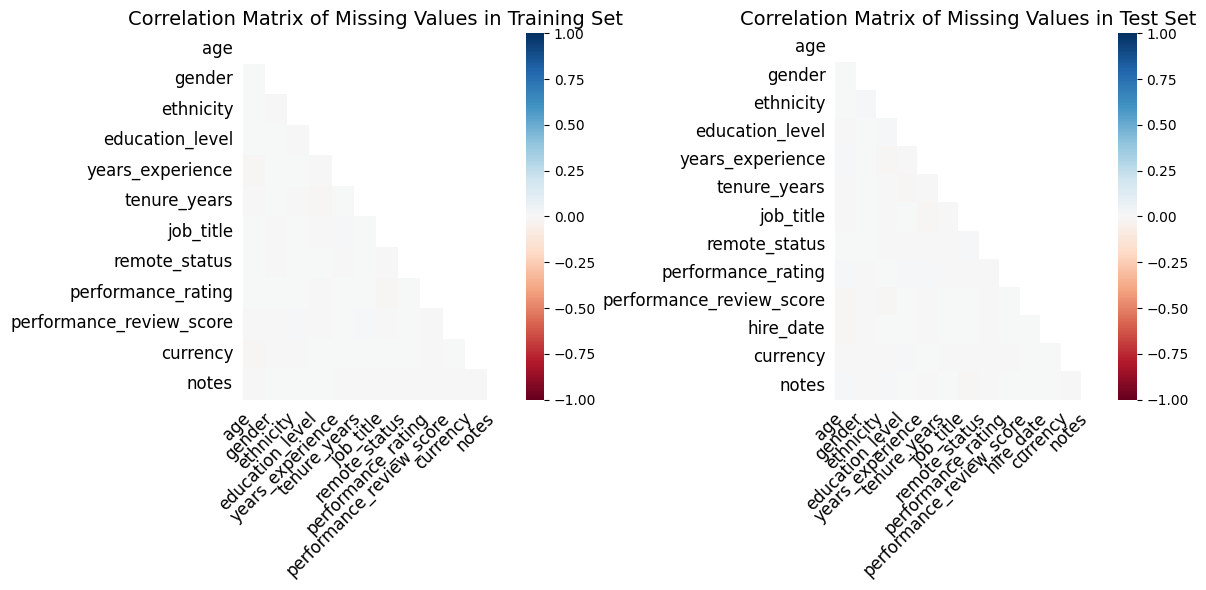

In [66]:
fig,ax = plt.subplots(1,2,figsize=(12,6))
msno.heatmap(df_train, ax=ax[0], fontsize=12)
ax[0].set_title('Correlation Matrix of Missing Values in Training Set', fontsize=14)
msno.heatmap(df_test, ax=ax[1], fontsize=12)
ax[1].set_title('Correlation Matrix of Missing Values in Test Set', fontsize=14)
plt.tight_layout()

/home/ryz/miniforge3/envs/dsml/lib/python3.10/site-packages/missingno/missingno.py:61: UserWarning: Plotting a sparkline on an existing axis is not currently supported. To remove this warning, set sparkline=False.
  warnings.warn(
/home/ryz/miniforge3/envs/dsml/lib/python3.10/site-packages/missingno/missingno.py:61: UserWarning: Plotting a sparkline on an existing axis is not currently supported. To remove this warning, set sparkline=False.
  warnings.warn(


Text(0.5, 1.0, 'Missing Values Matrix in Test Set')

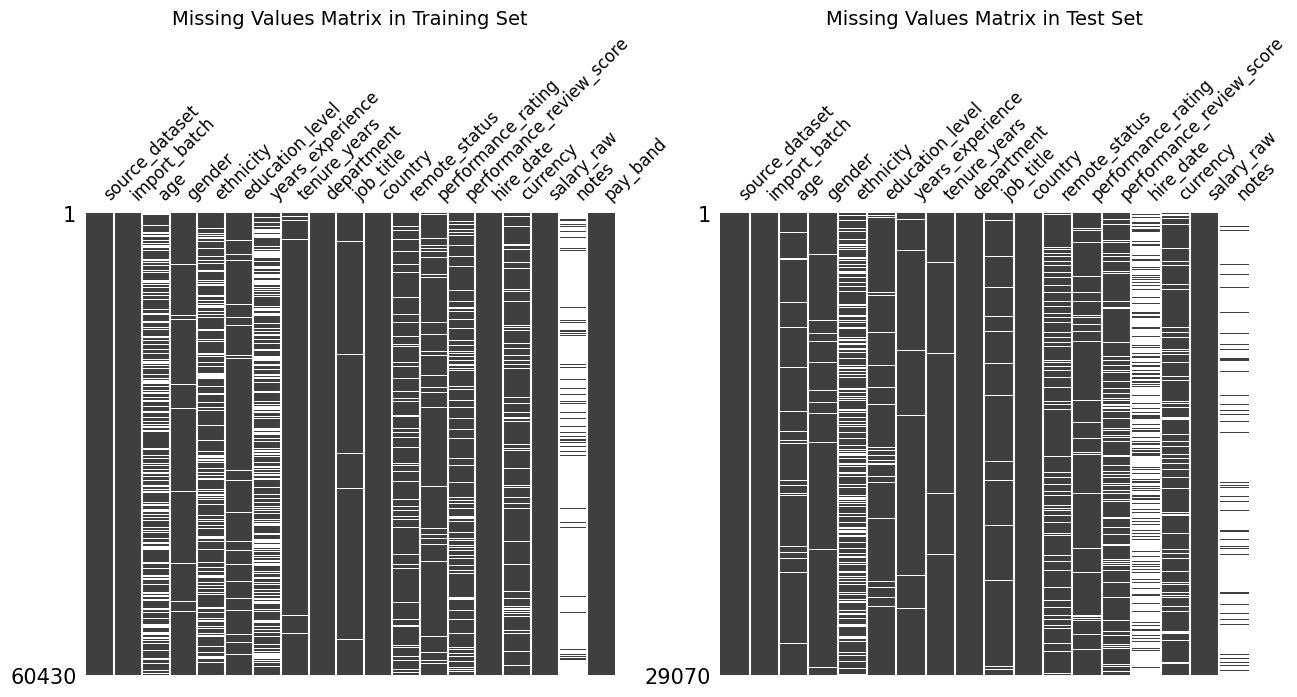

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
msno.matrix(df_train, ax=axes[0], fontsize=12)
axes[0].set_title('Missing Values Matrix in Training Set', fontsize=14)
msno.matrix(df_test, ax=axes[1], fontsize=12)
axes[1].set_title('Missing Values Matrix in Test Set', fontsize=14)

all missing consider as MCAR

In [68]:
df_train.drop(columns=['notes'], inplace=True)
df_test.drop(columns=['notes'], inplace=True)

### Numeric Distribution Analysis

In [69]:
numeric_cols = df_test.select_dtypes(include=[float, int]).columns.tolist()
num_numeric_cols = len(numeric_cols)

print(f"Number of numeric columns: {num_numeric_cols}")

Number of numeric columns: 5


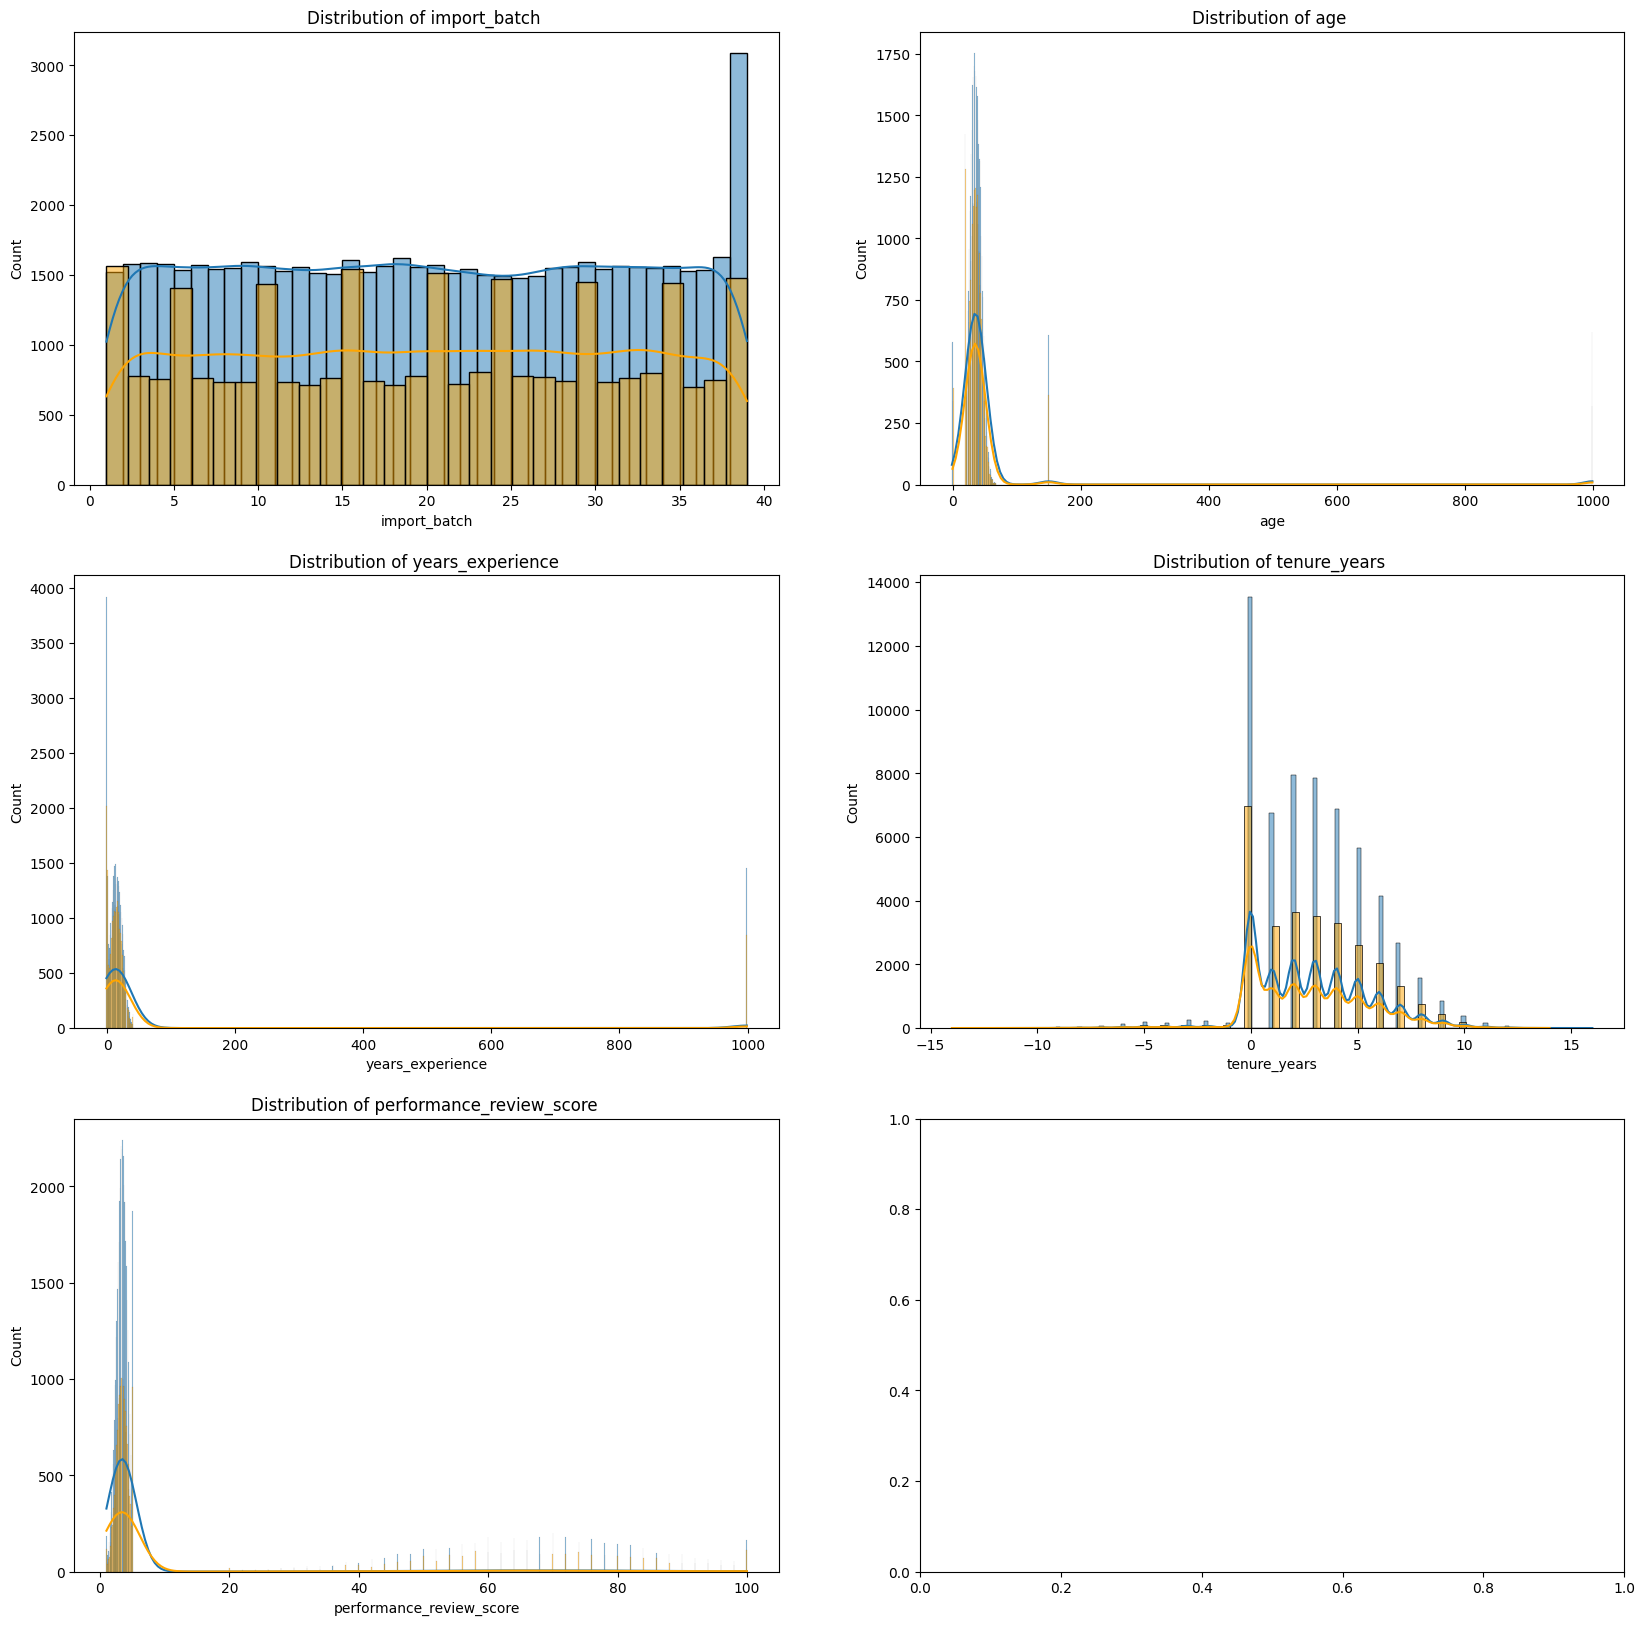

In [70]:
fig, axes = plt.subplots(3,2, figsize=(20, 20))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(df_train[col].dropna(), kde=True, ax=axes[i])
    sns.histplot(df_test[col].dropna(), kde=True, ax=axes[i], color='orange')
    axes[i].set_title(f'Distribution of {col} ')

In [71]:
display(df_train.describe())
display(df_test.describe())

,import_batch,age,years_experience,tenure_years,performance_review_score,hire_date
count,60430.000000,40919.000000,38853.000000,59842.000000,50784.000000,60430
mean,19.983336,51.406510,50.295524,2.806708,8.522141,2023-03-24 19:24:04.884990720
min,1.000000,-1.000000,-1.000000,-12.000000,1.000000,2010-06-25 00:00:00
25%,10.000000,30.000000,6.000000,1.000000,2.900000,2021-06-19 00:00:00
50%,20.000000,36.000000,14.000000,3.000000,3.500000,2023-06-27 00:00:00
75%,30.000000,43.000000,21.000000,5.000000,4.200000,2025-06-07 00:00:00
max,39.000000,999.000000,999.000000,16.000000,100.000000,2026-12-25 00:00:00
std,11.277795,118.804996,187.232439,2.707436,18.107695,NaN


,import_batch,age,years_experience,tenure_years,performance_review_score,hire_date
count,29070.000000,28208.000000,28777.000000,28758.000000,24652.000000,6875
mean,19.963364,47.183884,42.535115,2.757563,9.639080,2023-03-18 10:49:56.247272704
min,1.000000,0.000000,-1.000000,-14.000000,1.000000,2012-02-10 00:00:00
25%,10.000000,29.000000,7.000000,0.000000,2.900000,2021-05-21 00:00:00
50%,20.000000,35.000000,14.000000,2.000000,3.500000,2023-06-27 00:00:00
75%,30.000000,42.000000,21.000000,5.000000,4.300000,2025-07-03 12:00:00
max,39.000000,999.000000,999.000000,14.000000,100.000000,2026-12-19 00:00:00
std,11.252900,103.440138,166.715563,2.743422,19.819608,NaN


In [72]:
# Do some preprocessing on the data that, have abnormal range like, the age > 100

# Fix the error in the age and years_experience columns by replacing values greater than 100 with NaN

cols = ['age', 'years_experience', 'tenure_years']
for col in cols:
  df_train.loc[df_train[col] > 100, col] = np.nan
  df_test.loc[df_test[col] > 100, col] = np.nan

  df_train.loc[df_train[col] < 0, col] = np.nan
  df_test.loc[df_test[col] < 0, col] = np.nan

df_train.loc[df_train["age"] < 14, "age"] = np.nan
df_test.loc[df_test["age"] < 14, "age"] = np.nan

display(df_train.describe())
display(df_test.describe())

,import_batch,age,years_experience,tenure_years,performance_review_score,hire_date
count,60430.000000,38536.000000,33478.000000,58561.000000,50784.000000,60430
mean,19.983336,36.160914,15.129548,2.952699,8.522141,2023-03-24 19:24:04.884990720
min,1.000000,20.000000,0.000000,0.000000,1.000000,2010-06-25 00:00:00
25%,10.000000,30.000000,9.000000,1.000000,2.900000,2021-06-19 00:00:00
50%,20.000000,36.000000,15.000000,3.000000,3.500000,2023-06-27 00:00:00
75%,30.000000,42.000000,21.000000,5.000000,4.200000,2025-06-07 00:00:00
max,39.000000,68.000000,40.000000,16.000000,100.000000,2026-12-25 00:00:00
std,11.277795,8.591980,8.670410,2.528988,18.107695,NaN


,import_batch,age,years_experience,tenure_years,performance_review_score,hire_date
count,29070.000000,26790.000000,25915.000000,28118.000000,24652.000000,6875
mean,19.963364,35.664091,14.697858,2.910449,9.639080,2023-03-18 10:49:56.247272704
min,1.000000,20.000000,0.000000,0.000000,1.000000,2012-02-10 00:00:00
25%,10.000000,30.000000,8.000000,1.000000,2.900000,2021-05-21 00:00:00
50%,20.000000,36.000000,14.000000,3.000000,3.500000,2023-06-27 00:00:00
75%,30.000000,42.000000,21.000000,5.000000,4.300000,2025-07-03 12:00:00
max,39.000000,68.000000,40.000000,14.000000,100.000000,2026-12-19 00:00:00
std,11.252900,8.661743,8.691496,2.555696,19.819608,NaN


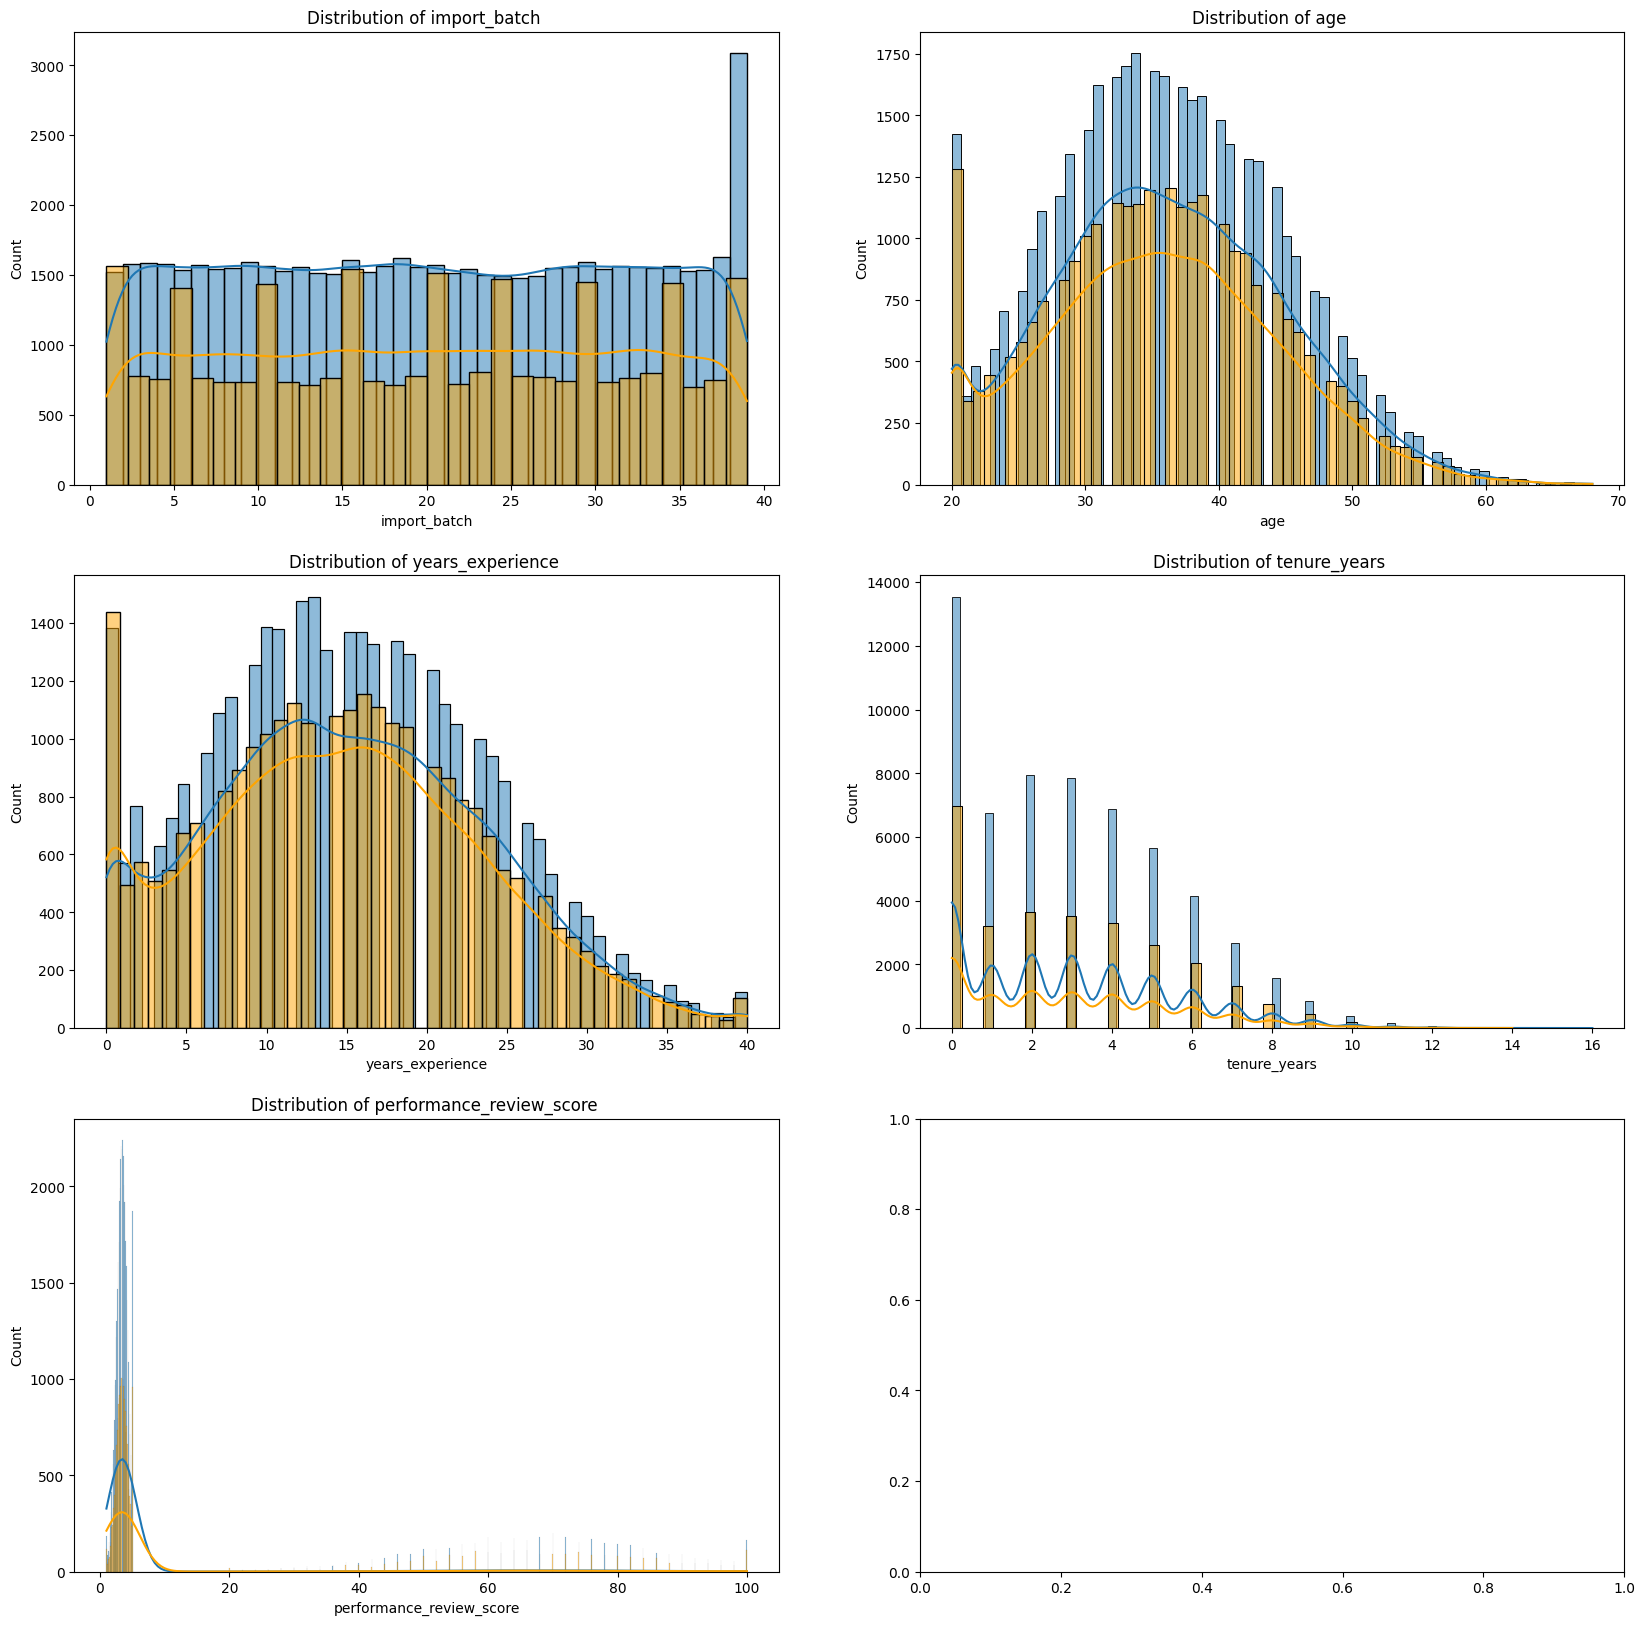

In [73]:
fig, axes = plt.subplots(3,2, figsize=(20, 20))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(df_train[col].dropna(), kde=True, ax=axes[i])
    sns.histplot(df_test[col].dropna(), kde=True, ax=axes[i], color='orange')
    axes[i].set_title(f'Distribution of {col} ')

### Cardinality Analysis

In [74]:
cat_cols = df_test.select_dtypes(include=['object']).columns.tolist()
cat_cols

['source_dataset',
 'gender',
 'ethnicity',
 'education_level',
 'department',
 'job_title',
 'country',
 'remote_status',
 'performance_rating',
 'currency',
 'salary_raw']

In [75]:
# remove all symbols and special characters from the categorical columns in both train and test sets

for col in cat_cols:
    df_train[col] = df_train[col].str.replace(r'[^a-zA-Z0-9\s]', '', regex=True).str.upper()
    df_test[col] = df_test[col].str.replace(r'[^a-zA-Z0-9\s]', '', regex=True).str.upper()

In [76]:
# Cardinality of categorical columns
train_cardinality = {col: df_train[col].nunique() for col in cat_cols}
test_cardinality = {col: df_test[col].nunique() for col in cat_cols}

cardinality_df = pd.DataFrame({
    'column_name': cat_cols,
    'train_cardinality': [train_cardinality[col] for col in cat_cols],
    'test_cardinality': [test_cardinality[col] for col in cat_cols]
}).sort_values(by='train_cardinality', ascending=False)

cardinality_df

,column_name,train_cardinality,test_cardinality
10,salary_raw,55074,27589
5,job_title,342,330
4,department,48,48
6,country,36,36
9,currency,12,12
1,gender,10,10
2,ethnicity,8,8
3,education_level,8,8
8,performance_rating,5,5
7,remote_status,4,4


### Target Distribution

/tmp/ipykernel_62711/1560612110.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=TARGET, data=df_train, palette='viridis')


Text(0.5, 1.0, 'Distribution of Target Variable')

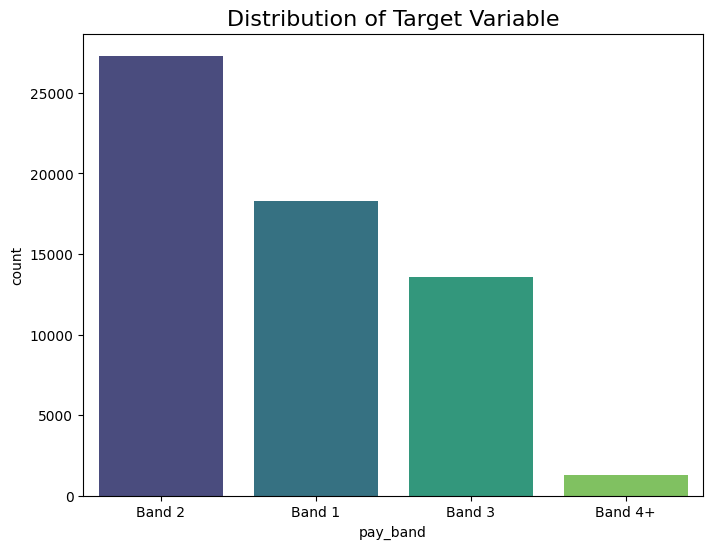

In [77]:
# Target Distribution
plt.figure(figsize=(8, 6))
sns.countplot(x=TARGET, data=df_train, palette='viridis')
plt.title('Distribution of Target Variable', fontsize=16)

band 4+ is imbalance

## Preprocessing

### Low Cardinality Cleaning

In [78]:
# Make the UNKNOWN to missing value for all
for col in cat_cols:
    df_train[col] = df_train[col].replace('UNKNOWN', np.nan)
    df_test[col] = df_test[col].replace('UNKNOWN', np.nan)

In [79]:
least_cardinality_cols = cardinality_df[cardinality_df['train_cardinality'] < 20].column_name.tolist()

for col in least_cardinality_cols:
    print(f"Unique values of {col} in Training Set:")
    print(df_train[col].unique())
    print()
    print()

Unique values of currency in Training Set:
['PHP' 'BRL' nan 'USD' 'EUR' 'KES' 'CAD' 'GBP' 'ZAR' 'NGN' 'SGD' 'AUD'
 'INR']


Unique values of gender in Training Set:
[nan 'FEMALE' 'WOMAN' 'OTHER' 'M' 'F' 'MALE' 'MAN' 'NB' 'NONBINARY'
 'PREFER NOT TO SAY']


Unique values of ethnicity in Training Set:
[nan 'WHITE' 'ASIAN' 'BLACK OR AFRICAN AMERICAN' 'TWO OR MORE RACES'
 'PACIFIC ISLANDER' 'NATIVE AMERICAN' 'PREFER NOT TO SAY'
 'HISPANIC OR LATINO']


Unique values of education_level in Training Set:
['BACHELORS DEGREE' 'ASSOCIATE DEGREE' 'PHD' 'MSC' 'BSC' 'HIGH SCHOOL'
 'BACHELORS' 'MASTERS' nan]


Unique values of performance_rating in Training Set:
['EXCEEDS' 'MEETS EXPECTATIONS' nan 'EXCEEDS EXPECTATIONS'
 'BELOW EXPECTATIONS' 'MEETS']


Unique values of remote_status in Training Set:
['HYBRID' 'ON SITE' 'REMOTE' 'ONSITE' nan]


Unique values of source_dataset in Training Set:
['HRISEXPORT2023' 'ACQUIREDCOMPANYLEGACY' 'SURVEYRESPONSE2024']




In [80]:
def clean_dataframe(df, is_train=True):
    df = df.copy()

    # ---------- Normalize string columns (strip, upper, collapse spaces) ----------
    cat_cols = ['currency', 'gender', 'ethnicity', 'education_level',
                'performance_rating', 'remote_status', 'notes', 'source_dataset']
    for col in cat_cols:
        if col in df.columns:
            df[col] = (df[col]
                       .astype(str)
                       .str.strip()
                       .str.upper()
                       .str.replace(r'\s+', ' ', regex=True)
                       .replace({'NAN': np.nan, 'NONE': np.nan, '': np.nan}))

    # ---------- currency ----------
    if 'currency' in df.columns:
        curr_map = {
            'PHP': 'PHP', 'BRL': 'BRL', 'USD': 'USD', 'EUR': 'EUR',
            'KES': 'KES', 'CAD': 'CAD', 'GBP': 'GBP', 'ZAR': 'ZAR',
            'NGN': 'NGN', 'SGD': 'SGD', 'AUD': 'AUD', 'INR': 'INR',
            'R$': 'BRL', '₱': 'PHP', '$': 'USD', '€': 'EUR', '£': 'GBP',
        }
        df['currency'] = df['currency'].replace(curr_map)
        df.loc[~df['currency'].isin(curr_map.values()), 'currency'] = np.nan

    # ---------- gender ----------
    if 'gender' in df.columns:
        gender_map = {
            'FEMALE': 'FEMALE', 'WOMAN': 'FEMALE', 'F': 'FEMALE',
            'MALE': 'MALE',     'MAN': 'MALE',     'M': 'MALE',
            'OTHER': 'OTHER',
            'NB': 'NONBINARY',  'NONBINARY': 'NONBINARY',
            'NON-BINARY': 'NONBINARY', 'NON BINARY': 'NONBINARY',
            'PREFER NOT TO SAY': 'PREFER NOT TO SAY',
        }
        df['gender'] = df['gender'].replace(gender_map)

    # ---------- ethnicity ----------
    if 'ethnicity' in df.columns:
        eth_map = {
            'WHITE': 'WHITE',
            'ASIAN': 'ASIAN',
            'BLACK OR AFRICAN AMERICAN': 'BLACK OR AFRICAN AMERICAN',
            'BLACK': 'BLACK OR AFRICAN AMERICAN',
            'AFRICAN AMERICAN': 'BLACK OR AFRICAN AMERICAN',
            'TWO OR MORE RACES': 'TWO OR MORE RACES',
            'MULTIRACIAL': 'TWO OR MORE RACES',
            'PACIFIC ISLANDER': 'PACIFIC ISLANDER',
            'NATIVE AMERICAN': 'NATIVE AMERICAN',
            'HISPANIC OR LATINO': 'HISPANIC OR LATINO',
            'HISPANIC': 'HISPANIC OR LATINO',
            'LATINO': 'HISPANIC OR LATINO',
            'PREFER NOT TO SAY': 'PREFER NOT TO SAY',
        }
        df['ethnicity'] = df['ethnicity'].replace(eth_map)

    # ---------- education_level ----------
    if 'education_level' in df.columns:
        edu_map = {
            'HIGH SCHOOL': 'HIGH SCHOOL',
            'ASSOCIATE DEGREE': 'ASSOCIATE DEGREE',
            'ASSOCIATES': 'ASSOCIATE DEGREE',
            'BACHELORS DEGREE': 'BACHELORS DEGREE',
            'BACHELORS': 'BACHELORS DEGREE',
            'BSC': 'BACHELORS DEGREE',
            'MASTERS': 'MASTERS DEGREE',
            'MSC': 'MASTERS DEGREE',
            'MASTERS DEGREE': 'MASTERS DEGREE',
            'PHD': 'PHD',
            'DOCTORATE': 'PHD',
        }
        df['education_level'] = df['education_level'].replace(edu_map)

    # ---------- performance_rating ----------
    if 'performance_rating' in df.columns:
        perf_map = {
            'EXCEEDS': 'EXCEEDS',
            'EXCEEDS EXPECTATIONS': 'EXCEEDS',
            'MEETS': 'MEETS',
            'MEETS EXPECTATIONS': 'MEETS',
            'BELOW EXPECTATIONS': 'BELOW',
            'BELOW': 'BELOW',
        }
        df['performance_rating'] = df['performance_rating'].replace(perf_map)

    # ---------- remote_status ----------
    if 'remote_status' in df.columns:
        remote_map = {
            'REMOTE': 'REMOTE',
            'HYBRID': 'HYBRID',
            'ON SITE': 'ONSITE',
            'ONSITE': 'ONSITE',
            'ON-SITE': 'ONSITE',
        }
        df['remote_status'] = df['remote_status'].replace(remote_map)

    # ---------- notes ----------
    if 'notes' in df.columns:
        notes_map = {
            'TBD': 'TBD',
            'MIGRATED': 'MIGRATED',
            'CHECK LATER': 'CHECK LATER',
            'VERIFIED': 'VERIFIED',
        }
        df['notes'] = df['notes'].replace(notes_map)
        # Optional: fill missing notes with a placeholder
        df['notes'] = df['notes'].fillna('UNKNOWN')

    # ---------- source_dataset ----------
    if 'source_dataset' in df.columns:
        src_map = {
            'HRISEXPORT2023': 'HRIS_EXPORT_2023',
            'ACQUIREDCOMPANYLEGACY': 'ACQUIRED_COMPANY_LEGACY',
            'SURVEYRESPONSE2024': 'SURVEY_RESPONSE_2024',
        }
        df['source_dataset'] = df['source_dataset'].replace(src_map)

    return df


df_train = clean_dataframe(df_train, is_train=True)
df_test  = clean_dataframe(df_test,  is_train=False)
shared_cat_cols = ['currency', 'gender', 'ethnicity', 'education_level',
                   'performance_rating', 'remote_status', 'notes', 'source_dataset']

for col in shared_cat_cols:
    if col in df_train.columns and col in df_test.columns:
        valid = set(df_train[col].dropna().unique())
        df_test.loc[~df_test[col].isin(valid) & df_test[col].notna(), col] = np.nan
    
for col in shared_cat_cols:
    if col in df_train.columns:
        print(f"\n--- {col} (train) ---")
        print(df_train[col].value_counts(dropna=False))
    if col in df_test.columns:
        print(f"--- {col} (test) ---")
        print(df_test[col].value_counts(dropna=False))


--- currency (train) ---
currency
USD    9382
EUR    9344
NaN    7325
GBP    6184
KES    3197
PHP    3185
ZAR    3177
SGD    3168
CAD    3144
BRL    3131
INR    3098
AUD    3096
NGN    2999
Name: count, dtype: int64
--- currency (test) ---
currency
EUR    4524
USD    4347
NaN    3533
GBP    3073
INR    1556
AUD    1553
ZAR    1549
NGN    1548
KES    1528
CAD    1487
BRL    1471
PHP    1465
SGD    1436
Name: count, dtype: int64

--- gender (train) ---
gender
MALE                 30410
FEMALE               25871
NaN                   1801
NONBINARY             1399
PREFER NOT TO SAY      482
OTHER                  467
Name: count, dtype: int64
--- gender (test) ---
gender
MALE                 14593
FEMALE               12406
NaN                    874
NONBINARY              696
OTHER                  256
PREFER NOT TO SAY      245
Name: count, dtype: int64

--- ethnicity (train) ---
ethnicity
WHITE                        20351
NaN                          15173
ASIAN                    

In [81]:
least_cardinality_cols = cardinality_df[cardinality_df['train_cardinality'] < 20].column_name.tolist()

for col in least_cardinality_cols:
    print(f"Unique values of {col} in Training Set:")
    print(df_train[col].unique())
    print()
    print()

Unique values of currency in Training Set:
['PHP' 'BRL' nan 'USD' 'EUR' 'KES' 'CAD' 'GBP' 'ZAR' 'NGN' 'SGD' 'AUD'
 'INR']


Unique values of gender in Training Set:
[nan 'FEMALE' 'OTHER' 'MALE' 'NONBINARY' 'PREFER NOT TO SAY']


Unique values of ethnicity in Training Set:
[nan 'WHITE' 'ASIAN' 'BLACK OR AFRICAN AMERICAN' 'TWO OR MORE RACES'
 'PACIFIC ISLANDER' 'NATIVE AMERICAN' 'PREFER NOT TO SAY'
 'HISPANIC OR LATINO']


Unique values of education_level in Training Set:
['BACHELORS DEGREE' 'ASSOCIATE DEGREE' 'PHD' 'MASTERS DEGREE'
 'HIGH SCHOOL' nan]


Unique values of performance_rating in Training Set:
['EXCEEDS' 'MEETS' nan 'BELOW']


Unique values of remote_status in Training Set:
['HYBRID' 'ONSITE' 'REMOTE' nan]


Unique values of source_dataset in Training Set:
['HRIS_EXPORT_2023' 'ACQUIRED_COMPANY_LEGACY' 'SURVEY_RESPONSE_2024']




### High Cardinality Cleaning

In [82]:
high_cardinality_cols = cardinality_df[cardinality_df['train_cardinality'] >= 20].column_name.tolist()

print("High Cardinality Columns:")
for col in high_cardinality_cols:
    print(f"{col}: {df_train[col].nunique()} unique values")
    print("Unique values in Training Set:")
    print(df_train[col].unique())
    print()

    print("Unique values in Test Set:")
    print(df_test[col].unique())

    print("\n" + "-"*50 + "\n")

High Cardinality Columns:
salary_raw: 55074 unique values
Unique values in Training Set:
['191210 PER MONTH' 'BRL 250722' '2827628' ... '3062203' '39289 GBP'
 '254750MONTH']

Unique values in Test Set:
['173K' '54935 EUR' '27740K' ... 'INR 3062190' '6859286' '266589MONTH']

--------------------------------------------------

job_title: 342 unique values
Unique values in Training Set:
['STAFF ENG' 'IT SUPPORT SPECIALIST' 'PARALEGAL' 'ML ENGINER'
 'GENERAL COUNSEL' 'SALES MANAGER' 'OPERATIONS MANAGER' 'COO' 'HR MANAGER'
 'OPERATIONS MGR' 'CUSTOMER  SUCCESS  MANAGER' 'PRODUCT DESIGNER'
 'LOGISTICS COORDINATOR' 'SENIOR DATA SCIENTIST' 'SALES DEVELOPMENT REP'
 'VP SALES' 'SYSTEMS ADMINISTRATOR' 'SEO SPECIALIST' 'ENGINEERING  MGR'
 'ML ENGINEER' 'STAFF ENGINER' 'UX DESIGNER' 'HR  BUSINESS  PARTNER'
 'IT MGR' 'SENIOR  PRODUCT  MANAGER' 'RECRUITER' 'QA ENG' 'ACCOUNTANT'
 'DEVOPS ENGINEER' 'VICE PRESIDENT PEOPLE' 'DESIGN LEAD' 'VP PRODUCT'
 'PRODUCT MGR' 'LOGISTICS COORD' 'CUSTOMER SUCCESS MANA

In [83]:
import re
import unicodedata
from decimal import Decimal, InvalidOperation

FX_TO_USD = {
    'USD': 1.0,
    'EUR': 1.08,
    'GBP': 1.27,
    'CAD': 0.73,
    'AUD': 0.66,
    'SGD': 0.74,
    'PHP': 0.017,
    'BRL': 0.20,
    'KES': 0.0078,
    'ZAR': 0.055,
    'NGN': 0.00065,
    'INR': 0.012,
}

CURRENCY_CODES = {
    "USD", "EUR", "GBP", "CAD", "AUD", "SGD",
    "PHP", "BRL", "KES", "ZAR", "NGN", "INR",
}

SYMBOL_CURRENCY = {
    "R$": "BRL",
    "₱": "PHP",
    "€": "EUR",
    "£": "GBP",
    "₹": "INR",
}

PERIOD_PATTERNS = {
    "monthly": r"PER\s*MONTH\b|MONTHLY\b|/\s*(?:MONTH|MO)\b|MONTH\b",
    "annual": r"PER\s*(?:YEAR|ANNUM)\b|ANNUALLY\b|ANNUAL\b|YEARLY\b|/\s*(?:YEAR|YR)\b",
    "weekly": r"PER\s*WEEK\b|WEEKLY\b|/\s*(?:WEEK|WK)\b",
    "daily": r"PER\s*DAY\b|DAILY\b|/\s*DAY\b",
    "hourly": r"PER\s*HOUR\b|HOURLY\b|/\s*(?:HOUR|HR)\b",
}

NUMBER_PATTERN = re.compile(
    r"(?<![\d.,])"
    r"(?P<number>[+-]?(?:\d+(?:[.,]\d+)*|[.,]\d+))"
    r"\s*(?P<suffix>[KM])?"
    r"(?![\d.,])"
)


def normalize_currency(value):
    if pd.isna(value):
        return None

    value = str(value).strip().upper()
    return value if value in CURRENCY_CODES else None


def parse_number_token(token, suffix=None):
    token = token.lstrip("+")
    suffix = (suffix or "").upper()

    if token.startswith("-"):
        raise ValueError("negative_salary")

    if "." in token and "," in token:
        decimal_sep = "." if token.rfind(".") > token.rfind(",") else ","
        grouping_sep = "," if decimal_sep == "." else "."

        integer, fraction = token.rsplit(decimal_sep, 1)

        if not fraction.isdigit() or len(fraction) > 2:
            raise ValueError("invalid_decimal_format")

        grouping_pattern = (
            rf"\d{{1,3}}(?:{re.escape(grouping_sep)}\d{{3}})+"
        )

        if not re.fullmatch(grouping_pattern, integer):
            raise ValueError("invalid_thousands_format")

        normalized = integer.replace(grouping_sep, "") + "." + fraction

    elif "." in token or "," in token:
        sep = "." if "." in token else ","
        parts = token.split(sep)

        if len(parts) > 2:
            if suffix:
                raise ValueError("ambiguous_number_with_suffix")

            grouping_pattern = rf"\d{{1,3}}(?:{re.escape(sep)}\d{{3}})+"

            if not re.fullmatch(grouping_pattern, token):
                raise ValueError("invalid_thousands_format")

            normalized = token.replace(sep, "")

        else:
            integer, fraction = parts

            if not fraction.isdigit():
                raise ValueError("invalid_number")

            if suffix:
                # 1.234K -> 1234; 0.125M -> 125000.
                # Separator tunggal dengan K/M dianggap desimal.
                if len(fraction) > 3:
                    raise ValueError("ambiguous_decimal_precision")

                normalized = (integer or "0") + "." + fraction

            elif len(fraction) == 3:
                # Tanpa konteks locale, 1.234 bisa desimal atau ribuan.
                raise ValueError("ambiguous_separator")

            elif len(fraction) <= 2:
                normalized = (integer or "0") + "." + fraction

            else:
                raise ValueError("ambiguous_decimal_precision")

    else:
        normalized = token

    try:
        amount = Decimal(normalized)
    except InvalidOperation:
        raise ValueError("invalid_number") from None

    multiplier = {
        "": Decimal("1"),
        "K": Decimal("1000"),
        "M": Decimal("1000000"),
    }[suffix]

    amount *= multiplier

    if not amount.is_finite() or amount <= 0:
        raise ValueError("nonpositive_or_invalid_salary")

    return amount


def parse_salary(val, currency_hint=None, default_period="annual"):
    def result(amount=np.nan, currency=None, period=None, status="invalid"):
        return {
            "amount_annual_local": amount,
            "currency": currency,
            "period": period,
            "status": status,
        }

    if default_period not in {None, "annual", "monthly"}:
        raise ValueError("default_period harus None, 'annual', atau 'monthly'")

    if pd.isna(val):
        return result(status="missing_salary")

    s = unicodedata.normalize("NFKC", str(val)).upper().strip()
    s = s.replace("\u2212", "-")
    s = re.sub(r"\s+", " ", s)

    if not s:
        return result(status="missing_salary")

    hint = normalize_currency(currency_hint)
    detected_currencies = set()

    for code in CURRENCY_CODES:
        pattern = rf"(?<![A-Z]){code}(?![A-Z])"

        if re.search(pattern, s):
            detected_currencies.add(code)
            s = re.sub(pattern, " ", s)

    for symbol, code in SYMBOL_CURRENCY.items():
        if symbol in s:
            detected_currencies.add(code)
            s = s.replace(symbol, " ")

    # R hanya diterima sebagai token mata uang di dekat angka.
    rand_pattern = r"(?<![A-Z])R(?=\s*\d)|(?<=\d)\s*R(?![A-Z])"

    if re.search(rand_pattern, s):
        detected_currencies.add("ZAR")
        s = re.sub(rand_pattern, " ", s)

    if len(detected_currencies) > 1:
        return result(status="conflicting_currency")

    explicit_currency = next(iter(detected_currencies), None)

    if explicit_currency and hint and explicit_currency != hint:
        return result(status="currency_hint_conflict")

    currency = explicit_currency or hint

    # $ sendiri ambigu: USD, CAD, AUD, SGD, dan lainnya.
    if "$" in s:
        if currency not in {"USD", "CAD", "AUD", "SGD"}:
            return result(status="ambiguous_dollar_currency")

        s = s.replace("$", " ")

    if currency is None:
        return result(status="missing_currency")

    detected_periods = []

    for period, pattern in PERIOD_PATTERNS.items():
        if re.search(pattern, s):
            detected_periods.append(period)
            s = re.sub(pattern, " ", s)

    if len(detected_periods) > 1:
        return result(currency=currency, status="conflicting_period")

    assumed_period = not detected_periods
    period = detected_periods[0] if detected_periods else default_period

    if period is None:
        return result(currency=currency, status="missing_period")

    if period not in {"annual", "monthly"}:
        return result(
            currency=currency,
            period=period,
            status="unsupported_period",
        )

    matches = list(NUMBER_PATTERN.finditer(s))

    if len(matches) != 1:
        return result(
            currency=currency,
            period=period,
            status="multiple_or_missing_numbers",
        )

    match = matches[0]
    remainder = s[:match.start()] + s[match.end():]

    # Jangan abaikan tahun, range, teks asing, atau tanda kurung.
    if remainder.strip():
        return result(
            currency=currency,
            period=period,
            status="unrecognized_text",
        )

    try:
        amount = parse_number_token(
            match.group("number"),
            match.group("suffix"),
        )
    except ValueError as exc:
        return result(
            currency=currency,
            period=period,
            status=str(exc),
        )

    if period == "monthly":
        amount *= Decimal("12")

    annual_amount = float(amount)

    if not np.isfinite(annual_amount):
        return result(currency=currency, period=period, status="overflow")

    return result(
        amount=annual_amount,
        currency=currency,
        period=period,
        status="ok_assumed_period" if assumed_period else "ok",
    )


def build_salary_usd(df_train, df_test, fx, default_period="annual"):
    fx_clean = {}

    for code, rate in fx.items():
        code = normalize_currency(code)
        rate = float(rate)

        if code is None or not np.isfinite(rate) or rate <= 0:
            raise ValueError("Mapping kurs mengandung kode/rate tidak valid")

        fx_clean[code] = rate

    def transform(df):
        df = df.copy()

        if "salary_raw" not in df.columns:
            raise KeyError("Kolom salary_raw tidak ditemukan")

        hints = (
            df["currency"].tolist()
            if "currency" in df.columns
            else [None] * len(df)
        )

        records = [
            parse_salary(raw, hint, default_period)
            for raw, hint in zip(df["salary_raw"].tolist(), hints)
        ]

        audit = pd.DataFrame(
            records,
            columns=["amount_annual_local", "currency", "period", "status"],
        )

        rates = audit["currency"].map(fx_clean)
        valid = audit["status"].isin(["ok", "ok_assumed_period"])

        audit.loc[valid & rates.isna(), "status"] = "missing_fx_rate"

        salary_usd = audit["amount_annual_local"] * rates
        invalid_usd = salary_usd.notna() & (
            ~np.isfinite(salary_usd) | (salary_usd <= 0)
        )

        audit.loc[invalid_usd, "status"] = "invalid_usd_amount"
        salary_usd = salary_usd.where(
            audit["status"].isin(["ok", "ok_assumed_period"])
        )

        df["salary_usd"] = salary_usd.to_numpy()

        # Audit dipisahkan agar tidak otomatis menjadi fitur model.
        audit.insert(0, "salary_raw", df["salary_raw"].to_numpy())
        audit.index = df.index

        df = df.drop(columns=["salary_raw", "currency"], errors="ignore")

        return df, audit

    train_out, train_audit = transform(df_train)
    test_out, test_audit = transform(df_test)

    return train_out, test_out, train_audit, test_audit


df_train, df_test, salary_audit_train, salary_audit_test = build_salary_usd(
    df_train,
    df_test,
    fx=FX_TO_USD,
    default_period="annual",
)

print(salary_audit_train["status"].value_counts(dropna=False))
print(salary_audit_test["status"].value_counts(dropna=False))

salary_problem_train = salary_audit_train.loc[
    ~salary_audit_train["status"].isin(["ok", "ok_assumed_period"])
]

salary_problem_test = salary_audit_test.loc[
    ~salary_audit_test["status"].isin(["ok", "ok_assumed_period"])
]

status
ok_assumed_period    45237
ok                   10704
missing_currency      4489
Name: count, dtype: int64
status
ok_assumed_period    21716
ok                    5171
missing_currency      2183
Name: count, dtype: int64


In [84]:
# =============================================================================
# JOB TITLE / DEPARTMENT / COUNTRY CLEANING  +  N-GRAM FEATURE ENGINEERING
# =============================================================================
import re
import numpy as np
import pandas as pd
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer


# =============================================================================
# 0. GENERIC HELPERS
# =============================================================================
def _normalize_str(x):
    """Uppercase, strip, remove junk punctuation, collapse whitespace. Empty -> NaN."""
    if pd.isna(x):
        return np.nan
    s = str(x).upper().strip()
    # keep letters, digits, spaces, and useful symbols (R&D, C++, /, -, ., &)
    s = re.sub(r"[^\w\s&/+.\-]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s if s else np.nan


# =============================================================================
# 1. JOB TITLE CLEANING
# =============================================================================
JOB_TITLE_RULES = [
    # ---------------- typo / misspelling ----------------
    (r'\bENGINERING\b',       'ENGINEERING'),
    (r'\bENGINER\b',          'ENGINEER'),
    (r'\bENGINEE?R?ING\b',    'ENGINEERING'),
    (r'\bANLST\b',            'ANALYST'),
    (r'\bANALIST\b',          'ANALYST'),
    (r'\bMANGER\b',           'MANAGER'),
    (r'\bMANAGMENT\b',        'MANAGEMENT'),
    (r'\bMGR\b',              'MANAGER'),
    (r'\bCORDINATOR\b',       'COORDINATOR'),
    (r'\bCOORD\b',            'COORDINATOR'),
    (r'\bDESGINER\b',         'DESIGNER'),
    (r'\bDESINGER\b',         'DESIGNER'),
    (r'\bSCIENTST\b',         'SCIENTIST'),
    (r'\bEXECTUIVE\b',        'EXECUTIVE'),
    (r'\bCOUNCEL\b',          'COUNSEL'),
    (r'\bSUPORT\b',           'SUPPORT'),
    (r'\bACOUNT(ANT|ING)\b',  r'ACCOUNT\1'),

    # ---------------- abbreviations ----------------
    (r'\bSVP\b',              'SENIOR VICE PRESIDENT'),
    (r'\bEVP\b',              'EXECUTIVE VICE PRESIDENT'),
    (r'\bVP\b',               'VICE PRESIDENT'),
    (r'\bSNR\b',              'SENIOR'),
    (r'\bSR\b',               'SENIOR'),
    (r'\bJR\b',               'JUNIOR'),
    (r'\bASST\b',             'ASSISTANT'),
    (r'\bASOC\b',             'ASSOCIATE'),
    (r'\bEXEC\b',             'EXECUTIVE'),
    (r'\bSPEC\b',             'SPECIALIST'),
    (r'\bENG\b',              'ENGINEER'),
    (r'\bREP\b',              'REPRESENTATIVE'),
    (r'\bDEV\b',              'DEVELOPMENT'),
    (r'\bSYS\b',              'SYSTEMS'),

    # ---------------- canonical synonyms ----------------
    (r'\bADMIN\b',            'ADMINISTRATOR'),   # unify ADMIN <-> ADMINISTRATOR
    (r'\bSOFTWARE DEV(ELOPER|ELOPMENT)?\b', 'SOFTWARE DEVELOPER'),
    (r'\bML\b',               'MACHINE LEARNING'),
    (r'\bQA\b',               'QUALITY ASSURANCE'),
    (r'\bHR\b',               'HUMAN RESOURCES'),
    (r'\bPR\b',               'PUBLIC RELATIONS'),
    (r'\bSEO\b',              'SEARCH ENGINE OPTIMIZATION'),
]

ROMAN_LEVELS = {
    'I': '1', 'II': '2', 'III': '3', 'IV': '4', 'V': '5',
    'VI': '6', 'VII': '7', 'VIII': '8', 'IX': '9', 'X': '10',
}
ROMAN_RE = re.compile(r'\b(' + '|'.join(sorted(ROMAN_LEVELS.keys(), key=len, reverse=True)) + r')\b')


def clean_job_title(x):
    s = _normalize_str(x)
    if pd.isna(s):
        return np.nan
    for pat, rep in JOB_TITLE_RULES:
        s = re.sub(pat, rep, s)
    # normalize roman numeral level at the end, e.g. "SOFTWARE ENGINEER II"
    s = ROMAN_RE.sub(lambda m: f"LEVEL {ROMAN_LEVELS[m.group(1)]}", s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s if s else np.nan


# =============================================================================
# 2. SENIORITY EXTRACTION (ordinal ranking)
# =============================================================================
SENIORITY_MAP = {
    'C-LEVEL':                  100,
    'EXECUTIVE VICE PRESIDENT':  95,
    'SENIOR VICE PRESIDENT':     90,
    'VICE PRESIDENT':            85,
    'HEAD':                      80,
    'DIRECTOR':                  75,
    'CHIEF':                     70,
    'PRINCIPAL':                 65,
    'LEAD':                      60,
    'MANAGER':                   55,
    'SENIOR':                    50,
    'STAFF':                     45,
    'MID':                       40,
    'JUNIOR':                    30,
    'ASSOCIATE':                 28,
    'ASSISTANT':                 25,
    'INTERN':                    20,
    'ENTRY':                     15,
    'UNKNOWN':                   10,
}

C_LEVEL_RE = re.compile(r'\b(CEO|CFO|COO|CMO|CTO|CIO|CHRO|CRO|CPO|CDO|CLO|CISO)\b')

SENIORITY_KEYS = [
    'EXECUTIVE VICE PRESIDENT', 'SENIOR VICE PRESIDENT', 'VICE PRESIDENT',
    'HEAD', 'DIRECTOR', 'CHIEF', 'PRINCIPAL', 'LEAD', 'MANAGER',
    'SENIOR', 'STAFF', 'JUNIOR', 'ASSOCIATE', 'ASSISTANT', 'INTERN',
]


def extract_seniority(title):
    if pd.isna(title):
        return 'UNKNOWN', SENIORITY_MAP['UNKNOWN']
    t = title.upper()
    if C_LEVEL_RE.search(t):
        return 'C-LEVEL', SENIORITY_MAP['C-LEVEL']
    for key in SENIORITY_KEYS:
        if re.search(rf'\b{re.escape(key)}\b', t):
            return key, SENIORITY_MAP[key]
    return 'MID', SENIORITY_MAP['MID']


# =============================================================================
# 3. FUNCTION / DOMAIN EXTRACTION
# =============================================================================
DOMAIN_PATTERNS = [
    ('LEGAL',       r'\b(LEGAL|COUNSEL|PARALEGAL|ATTORNEY|LAWYER)\b'),
    ('FINANCE',     r'\b(FINANCE|FINANCIAL|CONTROLLER|ACCOUNTANT|ACCOUNTING|TREASURY|AUDIT)\b'),
    ('HR',          r'\b(HUMAN RESOURCES|RECRUITER|TALENT|PEOPLE|BENEFITS)\b'),
    ('DATA',        r'\b(DATA SCIENTIST|DATA ANALYST|DATA ENGINEER|MACHINE LEARNING|ANALYTICS|HEAD OF DATA)\b'),
    ('ENGINEERING', r'\b(ENGINEER|ENGINEERING|DEVELOPER|DEVOPS|SRE|SOFTWARE|QUALITY ASSURANCE)\b'),
    ('DESIGN',      r'\b(DESIGN|DESIGNER|UX|UI)\b'),
    ('PRODUCT',     r'\b(PRODUCT)\b'),
    ('SALES',       r'\b(SALES|ACCOUNT EXECUTIVE|ACCOUNT MANAGER|REVENUE)\b'),
    ('MARKETING',   r'\b(MARKETING|SEARCH ENGINE OPTIMIZATION|CONTENT|BRAND|GROWTH)\b'),
    ('SUPPORT',     r'\b(SUPPORT|CUSTOMER SUCCESS|CUSTOMER SERVICE|HELPDESK|SERVICE DESK)\b'),
    ('OPERATIONS',  r'\b(OPERATIONS|LOGISTICS|SUPPLY CHAIN)\b'),
    ('IT',          r'\b(IT|INFORMATION TECHNOLOGY|SYSTEMS ADMINISTRATOR)\b'),
]


def extract_domain(title):
    if pd.isna(title):
        return 'OTHER'
    t = title.upper()
    for name, pat in DOMAIN_PATTERNS:
        if re.search(pat, t):
            return name
    return 'OTHER'


# =============================================================================
# 4. DEPARTMENT CLEANING
# =============================================================================
DEPT_SUFFIX = re.compile(r'\b(DEPARTMENT|DEPT|TEAM)\b')

DEPT_SYNONYMS = [
    (r'\bIT\b',                   'INFORMATION TECHNOLOGY'),
    (r'\bHR\b',                   'HUMAN RESOURCES'),
    (r'\bENG\b',                  'ENGINEERING'),
    (r'\bENGINEERING\b',          'ENGINEERING'),
    (r'\bDEV\b',                  'DEVELOPMENT'),
    (r'\bOPS\b',                  'OPERATIONS'),
    (r'\bMKTG?\b',                'MARKETING'),
    (r'\bFIN\b',                  'FINANCE'),
    (r'\bCUST(OMER)?\s*(SVC|SERVICE)\b', 'CUSTOMER SERVICE'),
]


def clean_department(x):
    s = _normalize_str(x)
    if pd.isna(s):
        return np.nan
    for pat, rep in DEPT_SYNONYMS:
        s = re.sub(pat, rep, s)
    s = DEPT_SUFFIX.sub('', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s if s else np.nan


# =============================================================================
# 5. COUNTRY CLEANING
# =============================================================================
COUNTRY_MAP = {
    # ---- UNITED STATES ----
    'US': 'UNITED STATES', 'USA': 'UNITED STATES',
    'UNITED STATES': 'UNITED STATES',
    'UNITED STATES OF AMERICA': 'UNITED STATES',
    'AMERICA': 'UNITED STATES',
    # ---- UNITED KINGDOM ----
    'UK': 'UNITED KINGDOM', 'GB': 'UNITED KINGDOM',
    'UNITED KINGDOM': 'UNITED KINGDOM',
    'GREAT BRITAIN': 'UNITED KINGDOM',
    'ENGLAND': 'UNITED KINGDOM',
    # ---- BRAZIL ----
    'BR': 'BRAZIL', 'BRAZIL': 'BRAZIL', 'BRASIL': 'BRAZIL',
    # ---- PHILIPPINES ----
    'PH': 'PHILIPPINES', 'PHILIPPINES': 'PHILIPPINES',
    'PHILLIPINES': 'PHILIPPINES', 'THE PHILIPPINES': 'PHILIPPINES',
    # ---- INDIA ----
    'IN': 'INDIA', 'INDIA': 'INDIA', 'BHARAT': 'INDIA', 'HINDUSTAN': 'INDIA',
    # ---- AUSTRALIA ----
    'AU': 'AUSTRALIA', 'AUS': 'AUSTRALIA', 'AUSTRALIA': 'AUSTRALIA',
    # ---- SOUTH AFRICA ----
    'ZA': 'SOUTH AFRICA', 'S AFRICA': 'SOUTH AFRICA',
    'SOUTH AFRICA': 'SOUTH AFRICA', 'RSA': 'SOUTH AFRICA',
    # ---- NIGERIA ----
    'NG': 'NIGERIA', 'NIGERIA': 'NIGERIA',
    # ---- KENYA ----
    'KE': 'KENYA', 'KENYA': 'KENYA',
    # ---- NETHERLANDS ----
    'NL': 'NETHERLANDS', 'NETHERLANDS': 'NETHERLANDS',
    'HOLLAND': 'NETHERLANDS', 'THE NETHERLANDS': 'NETHERLANDS',
    # ---- CANADA ----
    'CA': 'CANADA', 'CANADA': 'CANADA',
    # ---- GERMANY ----
    'DE': 'GERMANY', 'GERMANY': 'GERMANY',
    'DEUTSCHLAND': 'GERMANY', 'BRD': 'GERMANY',
    # ---- SINGAPORE ----
    'SG': 'SINGAPORE', 'SINGAPORE': 'SINGAPORE',
    # ---- FRANCE ----
    'FR': 'FRANCE', 'FRANCE': 'FRANCE',
}


def clean_country(x):
    s = _normalize_str(x)
    if pd.isna(s):
        return np.nan
    return COUNTRY_MAP.get(s, s)


# =============================================================================
# 6. WRAPPER: applies cleaning + derived features
# =============================================================================
def clean_high_cardinality(df):
    df = df.copy()

    if 'job_title' in df.columns:
        df['job_title'] = df['job_title'].apply(clean_job_title)

        # Derived seniority
        sen = df['job_title'].apply(extract_seniority)
        df['seniority']      = sen.apply(lambda t: t[0])
        df['seniority_rank'] = sen.apply(lambda t: t[1]).astype('int16')

        # Derived domain
        df['job_domain'] = df['job_title'].apply(extract_domain)

        # High-tier flag (useful as a binary feature)
        df['is_high_tier'] = (df['seniority_rank'] >= 80).astype('int8')

    if 'department' in df.columns:
        df['department'] = df['department'].apply(clean_department)

    if 'country' in df.columns:
        df['country'] = df['country'].apply(clean_country)

    return df


# =============================================================================
# 7. N-GRAM FEATURE BUILDING (word + char TF-IDF)
# =============================================================================
def build_title_ngrams(df_train, df_test,
                       word_ngram=(1, 3),
                       char_ngram=(3, 5),
                       max_features_word=3000,
                       max_features_char=3000,
                       min_df=2):
    """
    Fit vectorizers on TRAIN only (to avoid leakage), transform both splits.
    Returns (Xtr_w, Xte_w, Xtr_c, Xte_c, word_vec, char_vec).
    """
    tr = df_train['job_title'].fillna('').str.upper()
    te = df_test ['job_title'].fillna('').str.upper()

    word_vec = TfidfVectorizer(
        analyzer='word',
        ngram_range=word_ngram,
        min_df=min_df,
        max_features=max_features_word,
        sublinear_tf=True,
        token_pattern=r'(?u)\b\w+\b',
    )
    Xtr_w = word_vec.fit_transform(tr)
    Xte_w = word_vec.transform(te)

    char_vec = TfidfVectorizer(
        analyzer='char_wb',
        ngram_range=char_ngram,
        min_df=min_df,
        max_features=max_features_char,
        sublinear_tf=True,
    )
    Xtr_c = char_vec.fit_transform(tr)
    Xte_c = char_vec.transform(te)

    return Xtr_w, Xte_w, Xtr_c, Xte_c, word_vec, char_vec


def build_full_feature_matrix(df_train, df_test):
    """
    Combine word n-grams + char n-grams + numeric seniority/domain one-hot.
    Returns (X_train, X_test, feature_names).
    """
    # --- text n-grams ---
    Xtr_w, Xte_w, Xtr_c, Xte_c, word_vec, char_vec = build_title_ngrams(df_train, df_test)

    # --- numeric derived features from job title ---
    num_cols = ['seniority_rank', 'is_high_tier']
    num_tr = csr_matrix(df_train[num_cols].fillna(0).astype('float32').values)
    num_te = csr_matrix(df_test [num_cols].fillna(0).astype('float32').values)

    # --- one-hot seniority & domain ---
    sen_dummies = pd.get_dummies(df_train['seniority'], prefix='sen').reindex(
        columns=[f'sen_{k}' for k in SENIORITY_MAP.keys()], fill_value=0)
    dom_dummies = pd.get_dummies(df_train['job_domain'], prefix='dom')
    # align test to train columns
    sen_te = pd.get_dummies(df_test['seniority'], prefix='sen').reindex(
        columns=sen_dummies.columns, fill_value=0)
    dom_te = pd.get_dummies(df_test['job_domain'], prefix='dom').reindex(
        columns=dom_dummies.columns, fill_value=0)

    ohe_tr = csr_matrix(np.hstack([sen_dummies.values, dom_dummies.values]).astype('float32'))
    ohe_te = csr_matrix(np.hstack([sen_te.values,       dom_te.values]).astype('float32'))

    # --- stack everything ---
    X_train = hstack([Xtr_w, Xtr_c, num_tr, ohe_tr]).tocsr()
    X_test  = hstack([Xte_w, Xte_c, num_te, ohe_te]).tocsr()

    feature_names = (
        [f'w_{t}' for t in word_vec.get_feature_names_out()] +
        [f'c_{t}' for t in char_vec.get_feature_names_out()] +
        num_cols +
        list(sen_dummies.columns) +
        list(dom_dummies.columns)
    )

    return X_train, X_test, feature_names


# ---------- cleaning ----------
df_train = clean_high_cardinality(df_train)
df_test  = clean_high_cardinality(df_test)

# ---------- reporting ----------
print("=" * 60)
print("JOB TITLE")
print("=" * 60)
print("Train unique:", df_train['job_title'].nunique(dropna=True))
print("Test  unique:", df_test ['job_title'].nunique(dropna=True))
print("\nValue counts train:\n", df_train['job_title'].value_counts(dropna=False).head(60))

print("\n" + "=" * 60)
print("SENIORITY")
print("=" * 60)
print(df_train['seniority'].value_counts(dropna=False))

print("\n" + "=" * 60)
print("DOMAIN")
print("=" * 60)
print(df_train['job_domain'].value_counts(dropna=False))

print("\n" + "=" * 60)
print("DEPARTMENT")
print("=" * 60)
print("Train unique:", df_train['department'].nunique(dropna=True))
print("Test  unique:", df_test ['department'].nunique(dropna=True))
print("\nValue counts train:\n", df_train['department'].value_counts(dropna=False))

print("\n" + "=" * 60)
print("COUNTRY")
print("=" * 60)
print("Train unique:", df_train['country'].nunique(dropna=True))
print("Test  unique:", df_test ['country'].nunique(dropna=True))
print("\nValue counts train:\n", df_train['country'].value_counts(dropna=False))
print("\nValue counts test:\n",  df_test ['country'].value_counts(dropna=False))

# ---------- leakage check ----------
for col in ['job_title', 'department', 'country', 'seniority', 'job_domain']:
    if col in df_train.columns and col in df_test.columns:
        train_vals = set(df_train[col].dropna().unique())
        test_only  = set(df_test [col].dropna().unique()) - train_vals
        if test_only:
            print(f"\n[WARN] {col}: value in test not in train -> {sorted(test_only)}")
        else:
            print(f"\n[OK] {col}: all test values exist in train.")

# ---------- n-gram feature matrices ----------
X_train, X_test, feature_names = build_full_feature_matrix(df_train, df_test)
print("\n" + "=" * 60)
print("FEATURE MATRIX")
print("=" * 60)
print("X_train shape:", X_train.shape)
print("X_test  shape:", X_test.shape)
print("n_features   :", len(feature_names))

# ---------- quick tier sanity check ----------
tier = np.where(df_train['seniority_rank'] >= 80, 'HIGH',
            np.where(df_train['job_domain'].isin(['ENGINEERING', 'IT', 'SUPPORT']),
                    'ENG/ADMIN', 'OTHER'))
print("\nTier distribution:\n", pd.Series(tier).value_counts())

JOB TITLE
Train unique: 53
Test  unique: 53

Value counts train:
 job_title
IT MANAGER                               2002
CUSTOMER SUCCESS MANAGER                 1939
SUPPORT TEAM LEAD                        1742
PARALEGAL                                1540
SYSTEMS ADMINISTRATOR                    1538
GENERAL COUNSEL                          1488
SUPPORT AGENT                            1487
IT SUPPORT SPECIALIST                    1463
LEGAL COUNSEL                            1454
VICE PRESIDENT DESIGN                    1413
PRODUCT MANAGER                          1411
OPERATIONS MANAGER                       1406
COO                                      1386
VICE PRESIDENT PRODUCT                   1380
SENIOR PRODUCT MANAGER                   1377
DESIGN LEAD                              1311
NaN                                      1201
CFO                                      1144
PRODUCT ANALYST                          1130
VICE PRESIDENT SALES                     1129
VICE

In [85]:
high_cardinality_cols = cardinality_df[cardinality_df['train_cardinality'] >= 20].column_name.tolist()
high_cardinality_cols.remove('salary_raw')
print("High Cardinality Columns:")
for col in high_cardinality_cols:
    print(f"{col}: {df_train[col].nunique()} unique values")
    print("Unique values in Training Set:")
    print(df_train[col].unique())
    print()

    print("Unique values in Test Set:")
    print(df_test[col].unique())

    print("\n" + "-"*50 + "\n")

High Cardinality Columns:
job_title: 53 unique values
Unique values in Training Set:
['STAFF ENGINEER' 'IT SUPPORT SPECIALIST' 'PARALEGAL'
 'MACHINE LEARNING ENGINEER' 'GENERAL COUNSEL' 'SALES MANAGER'
 'OPERATIONS MANAGER' 'COO' 'HUMAN RESOURCES MANAGER'
 'CUSTOMER SUCCESS MANAGER' 'PRODUCT DESIGNER' 'LOGISTICS COORDINATOR'
 'SENIOR DATA SCIENTIST' 'SALES DEVELOPMENT REPRESENTATIVE'
 'VICE PRESIDENT SALES' 'SYSTEMS ADMINISTRATOR'
 'SEARCH ENGINE OPTIMIZATION SPECIALIST' 'ENGINEERING MANAGER'
 'UX DESIGNER' 'HUMAN RESOURCES BUSINESS PARTNER' 'IT MANAGER'
 'SENIOR PRODUCT MANAGER' 'RECRUITER' 'QUALITY ASSURANCE ENGINEER'
 'ACCOUNTANT' 'DEVOPS ENGINEER' 'VICE PRESIDENT PEOPLE' 'DESIGN LEAD'
 'VICE PRESIDENT PRODUCT' 'PRODUCT MANAGER' 'SOFTWARE ENGINEER LEVEL 2'
 'SUPPORT AGENT' 'LEGAL COUNSEL' nan 'CMO' 'HEAD OF DATA'
 'SENIOR SOFTWARE ENGINEER' 'CONTENT STRATEGIST' 'CFO' 'DATA ANALYST'
 'SUPPORT TEAM LEAD' 'CONTROLLER' 'SOFTWARE ENGINEER LEVEL 1'
 'FINANCIAL ANALYST' 'DATA SCIENTIST' 'M

### Encoding

In [86]:
cat_cols = df_test.select_dtypes(include=['object']).columns.tolist()

cardinality_df = pd.DataFrame({
    'column_name': cat_cols,
    'train_cardinality': [df_train[col].nunique() for col in cat_cols],
    'test_cardinality': [df_test[col].nunique() for col in cat_cols]
}).sort_values(by='train_cardinality', ascending=False)

low_cardinality_cols = cardinality_df[cardinality_df['train_cardinality'] < 20].column_name.tolist()
high_cardinality_cols = cardinality_df[cardinality_df['train_cardinality'] >= 20].column_name.tolist()

for col in low_cardinality_cols:
    print(f"{col}: {df_train[col].nunique()} unique values")

for col in high_cardinality_cols:
    print(f"{col}: {df_train[col].nunique()} unique values")

country: 14 unique values
job_domain: 13 unique values
department: 12 unique values
seniority: 9 unique values
ethnicity: 8 unique values
gender: 5 unique values
education_level: 5 unique values
source_dataset: 3 unique values
performance_rating: 3 unique values
remote_status: 3 unique values
job_title: 53 unique values


In [87]:
df_train[cat_cols].fillna('__MISSING__')
df_test[cat_cols].fillna('__MISSING__')

# low cardinality columns -> OHE
df_train = pd.get_dummies(df_train, columns=low_cardinality_cols)
df_test = pd.get_dummies(df_test, columns=low_cardinality_cols)

### Missing Imputation

In [88]:
train_missing = df_train.isnull().sum()
test_missing = df_test.isnull().sum()
train_missing = train_missing[train_missing > 0]
test_missing = test_missing[test_missing > 0]

train_missing_percent = (train_missing / len(df_train)) * 100
test_missing_percent = (test_missing / len(df_test)) * 100

train_missing_df = pd.DataFrame({'column_name': train_missing.index, 'missing_count': train_missing.values, 'missing_percent': train_missing_percent.values}).sort_values(by='missing_count', ascending=False)
test_missing_df = pd.DataFrame({'column_name': test_missing.index, 'missing_count': test_missing.values, 'missing_percent': test_missing_percent.values}).sort_values(by='missing_count', ascending=False)

display(train_missing_df)
display(test_missing_df)

,column_name,missing_count,missing_percent
1,years_experience,26952,44.600364
0,age,21894,36.230349
4,performance_review_score,9646,15.962270
5,salary_usd,4489,7.428430
2,tenure_years,1869,3.092835
3,job_title,1201,1.987423


,column_name,missing_count,missing_percent
5,hire_date,22195,76.350189
4,performance_review_score,4418,15.197798
1,years_experience,3155,10.853113
0,age,2280,7.843137
6,salary_usd,2183,7.509460
2,tenure_years,952,3.274854
3,job_title,607,2.088063


looks like the hire date not very informative

In [89]:
df_train.drop(columns=["hire_date"], inplace=True)
df_test.drop(columns=["hire_date"], inplace=True)

In [90]:
MISSING_TOKEN = "__MISSING__"
BASE_NUMERIC_COLS = [
    "age",
    "years_experience",
    "tenure_years",
    "performance_review_score",
    "salary_usd",
]


def handle_missing_catboost(
    df,
    cat_cols,
    numeric_cols,
    indicator_cols,
    target_col=TARGET,
):
    df = df.copy()

    # Target is never imputed or transformed.
    if target_col in df.columns and df[target_col].isna().any():
        raise ValueError(f"Target '{target_col}' contains missing values.")

    for col in numeric_cols:
        values = pd.to_numeric(
            df[col],
            errors="raise",
        ).astype("float64")

        df[col] = values.where(np.isfinite(values))

    # Explicit missing indicators for selected base features.
    for col in indicator_cols:
        indicator_name = f"{col}_missing"

        if indicator_name not in df.columns:
            df[indicator_name] = df[col].isna().astype("int8")

    # Missing categories become a dedicated category, not the mode.
    for col in cat_cols:
        values = df[col].astype("string").str.strip()
        values = values.mask(values.eq(""), pd.NA)

        df[col] = (
            values
            .fillna(MISSING_TOKEN)
            .astype(str)
        )

    return df


# Derive the feature schema from TRAIN, excluding the target.
feature_cols = [
    col for col in df_train.columns
    if col != TARGET
]

test_feature_cols = [
    col for col in df_test.columns
    if col != TARGET
]

missing_in_test = sorted(set(feature_cols) - set(test_feature_cols))
extra_in_test = sorted(set(test_feature_cols) - set(feature_cols))

if missing_in_test or extra_in_test:
    raise ValueError(
        "Train-test feature schema differs.\n"
        f"Missing in test: {missing_in_test}\n"
        f"Extra in test: {extra_in_test}"
    )

cat_cols = df_train[feature_cols].select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numeric_cols = df_train[feature_cols].select_dtypes(
    include=["number", "bool"]
).columns.tolist()

unsupported_cols = sorted(
    set(feature_cols) - set(cat_cols) - set(numeric_cols)
)

if unsupported_cols:
    raise TypeError(
        "Convert or remove unsupported feature types first: "
        f"{unsupported_cols}"
    )

indicator_cols = [
    col for col in BASE_NUMERIC_COLS
    if col in numeric_cols
]

df_train = handle_missing_catboost(
    df_train,
    cat_cols=cat_cols,
    numeric_cols=numeric_cols,
    indicator_cols=indicator_cols,
)

df_test = handle_missing_catboost(
    df_test,
    cat_cols=cat_cols,
    numeric_cols=numeric_cols,
    indicator_cols=indicator_cols,
)

# Diagnostic report: numeric missing values intentionally remain.
missing_report = pd.DataFrame({
    "train_numeric_missing": df_train[numeric_cols].isna().sum(),
    "test_numeric_missing": df_test[numeric_cols].isna().sum(),
})

print("Numeric missing values retained for CatBoost:")
print(
    missing_report.loc[
        missing_report.sum(axis=1) > 0
    ]
)

print("\nCategorical missing values remaining:")
print("Train:", int(df_train[cat_cols].isna().sum().sum()))
print("Test :", int(df_test[cat_cols].isna().sum().sum()))


Numeric missing values retained for CatBoost:
                          train_numeric_missing  test_numeric_missing
age                                       21894                  2280
years_experience                          26952                  3155
tenure_years                               1869                   952
performance_review_score                   9646                  4418
salary_usd                                 4489                  2183

Categorical missing values remaining:
Train: 0
Test : 0


### Feature Engineering

In [91]:
numeric_cols = df_test.select_dtypes(include=[float, int, bool]).columns.tolist()
cat_cols = df_test.select_dtypes(include=['object']).columns.tolist()

print(f"Numeric columns: {numeric_cols}")
print(f"Categorical columns: {cat_cols}")

Numeric columns: ['import_batch', 'age', 'years_experience', 'tenure_years', 'performance_review_score', 'salary_usd', 'seniority_rank', 'is_high_tier', 'country_AUSTRALIA', 'country_BRAZIL', 'country_CANADA', 'country_FRANCE', 'country_GERMANY', 'country_INDIA', 'country_KENYA', 'country_NETHERLANDS', 'country_NIGERIA', 'country_PHILIPPINES', 'country_SINGAPORE', 'country_SOUTH AFRICA', 'country_UNITED KINGDOM', 'country_UNITED STATES', 'job_domain_DATA', 'job_domain_DESIGN', 'job_domain_ENGINEERING', 'job_domain_FINANCE', 'job_domain_HR', 'job_domain_IT', 'job_domain_LEGAL', 'job_domain_MARKETING', 'job_domain_OPERATIONS', 'job_domain_OTHER', 'job_domain_PRODUCT', 'job_domain_SALES', 'job_domain_SUPPORT', 'department_CUSTOMER SUPPORT', 'department_DATA SCIENCE', 'department_DESIGN', 'department_ENGINEERING', 'department_FINANCE', 'department_HUMAN RESOURCES', 'department_INFORMATION TECHNOLOGY', 'department_LEGAL', 'department_MARKETING', 'department_OPERATIONS', 'department_PRODUCT'

In [92]:
# =============================================================================
# FEATURE ENGINEERING ONLY
# Target: pay_band
# =============================================================================
import re


# =============================================================================
# 1. FEATURE ENGINEERING
# =============================================================================
_RE_WS = re.compile(r'\s+')

_SEN_RE = {
    'intern':    re.compile(r'INTERN'),
    'junior':    re.compile(r'JUNIOR|\bJR\b'),
    'senior':    re.compile(r'SENIOR|\bSR\b'),
    'lead':      re.compile(r'LEAD'),
    'staff':     re.compile(r'STAFF'),
    'principal': re.compile(r'PRINCIPAL'),
    'manager':   re.compile(r'MANAGER'),
    'director':  re.compile(r'DIRECTOR'),
    'head':      re.compile(r'HEAD'),
    'vp':        re.compile(r'VICE PRESIDENT|\bVP\b'),
    'c_level':   re.compile(r'CHIEF|\bCEO\b|\bCFO\b|\bCOO\b|\bCMO\b|\bCTO\b'),
}

_FAM_RE = {
    'engineering': re.compile(r'ENGINEER|DEVOPS|\bQA\b|SYSTEMS|\bIT\b'),
    'data':        re.compile(r'DATA|\bML\b|ANALYST|ANLST|SCIENTIST|SCIENTST'),
    'sales':       re.compile(r'SALES|ACCOUNT'),
    'marketing':   re.compile(r'MARKETING|SEO|CONTENT'),
    'finance':     re.compile(r'FINANCE|FINANCIAL|CONTROLLER|ACCOUNTANT'),
    'hr':          re.compile(r'\bHR\b|PEOPLE|RECRUITER'),
    'legal':       re.compile(r'LEGAL|COUNSEL|COUNCEL|PARALEGAL'),
    'design':      re.compile(r'DESIGN|\bUX\b'),
    'product':     re.compile(r'PRODUCT'),
    'operations':  re.compile(r'OPERATIONS|LOGISTICS'),
    'support':     re.compile(r'SUPPORT|CUSTOMER'),
    'c_suite':     re.compile(r'\bCEO\b|\bCFO\b|\bCOO\b|\bCMO\b|\bCTO\b|CHIEF'),
}


def engineer_features(df):
    df = df.copy()
    eps = 1e-6

    # ---- recover categorical from OHE ----
    for name in ['country', 'department', 'ethnicity', 'education_level',
                 'gender', 'source_dataset', 'remote_status', 'performance_rating']:
        cols = [c for c in df.columns if c.startswith(f'{name}_')]
        if cols:
            cat = df[cols].idxmax(axis=1).str.replace(f'{name}_', '', regex=False)
            df[f'cat_{name}'] = cat.where(df[cols].sum(axis=1) > 0, 'UNKNOWN')

    # ---- numeric ratios ----
    age  = df['age']
    exp  = df['years_experience']
    ten  = df['tenure_years']
    sal  = df['salary_usd']
    perf = df['performance_review_score']

    df['exp_over_age']      = exp / (age + eps)
    df['tenure_over_age']   = ten / (age + eps)
    df['tenure_over_exp']   = ten / (exp + eps)
    df['age_minus_exp']     = age - exp
    df['age_minus_tenure']  = age - ten
    df['exp_minus_tenure']  = exp - ten
    df['career_start_age']  = age - exp

    df['salary_log']        = np.log1p(sal.clip(lower=0))
    df['salary_per_exp']    = sal / (exp + eps)
    df['salary_per_age']    = sal / (age + eps)
    df['salary_per_tenure'] = sal / (ten + eps)
    df['salary_x_perf']     = sal * perf
    df['salary_x_exp']      = sal * exp
    df['salary_rank_pct']   = sal.rank(pct=True)

    df['perf_x_exp']    = perf * exp
    df['perf_x_tenure'] = perf * ten
    df['perf_per_exp']  = perf / (exp + eps)

    for col in ['age', 'years_experience', 'salary_usd']:
        df[f'{col}_sq']  = df[col] ** 2
        df[f'{col}_log'] = np.log1p(df[col].clip(lower=0))

    # ---- job title ----
    jt = df['job_title'].fillna('').astype(str).str.upper()
    jt = jt.str.replace(_RE_WS, ' ', regex=True).str.strip()
    df['jt_len']        = jt.str.len()
    df['jt_word_count'] = jt.str.split().str.len()

    sen_map = {'intern': -3, 'junior': -1, 'senior': 2, 'lead': 3, 'staff': 3,
               'principal': 4, 'manager': 3, 'director': 5, 'head': 5,
               'vp': 6, 'c_level': 8}
    for k, rx in _SEN_RE.items():
        df[f'jt_sen_{k}'] = jt.str.contains(rx, regex=True).astype('int8')
    df['jt_seniority'] = sum(df[f'jt_sen_{k}'] * v for k, v in sen_map.items())

    for k, rx in _FAM_RE.items():
        df[f'jt_fam_{k}'] = jt.str.contains(rx, regex=True).astype('int8')

    df['jt_family'] = 'other'
    for k in ['c_suite', 'engineering', 'data', 'product', 'sales', 'marketing',
              'finance', 'hr', 'legal', 'design', 'operations', 'support']:
        mask = (df[f'jt_fam_{k}'] == 1) & (df['jt_family'] == 'other')
        df.loc[mask, 'jt_family'] = k

    # ---- cross-categorical ----
    df['x_country_dept']     = df['cat_country']    + '|' + df['cat_department']
    df['x_dept_family']      = df['cat_department'] + '|' + df['jt_family']
    df['x_family_seniority'] = df['jt_family']      + '|' + df['jt_seniority'].astype(str)

    # ---- ordinal interactions ----
    df['sen_x_exp']    = df['jt_seniority'] * exp
    df['sen_x_salary'] = df['jt_seniority'] * sal

    return df


df_train      = engineer_features(df_train)
df_test       = engineer_features(df_test)

print(f"Train: {df_train.shape[1]} -> {df_train.shape[1]}")
print(f"Test : {df_test.shape[1]} -> {df_test.shape[1]}")

Train: 153 -> 153
Test : 152 -> 152


## Modeling

Bebas memilih model ML (boleh *ensemble*), **asal bukan deep learning**.

**Pastikan sudah memiliki variabel berikut:**
`X_train, X_val, y_train, y_val -> df_train`

In [93]:
# =============================================================================
# CATBOOST PIPELINE — FIXED PARAMETERS + 5-FOLD CV
# =============================================================================
import copy
import joblib
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
)
N_SPLITS = 5
EARLY_STOPPING_ROUNDS = 50


# =============================================================================
# 1. PREPARE DATA
# =============================================================================
def prepare_catboost_data(
    df_train,
    df_test,
    target_col=TARGET,
    id_cols=None,
    drop_cols=None,
):
    id_cols = id_cols or []
    drop_cols = drop_cols or []

    y_train_raw = df_train[target_col].copy()

    if y_train_raw.isna().any():
        raise ValueError("Target training mengandung missing value.")

    X_train = df_train.drop(
        columns=[target_col] + id_cols + drop_cols,
        errors="ignore",
    ).copy()

    if target_col in df_test.columns:
        y_test_raw = df_test[target_col].copy()
    else:
        y_test_raw = None

    X_test = df_test.drop(
        columns=[target_col] + id_cols + drop_cols,
        errors="ignore",
    ).copy()

    if not X_train.columns.is_unique or not X_test.columns.is_unique:
        raise ValueError("Nama kolom fitur harus unik.")

    missing_in_test = X_train.columns.difference(X_test.columns)
    extra_in_test = X_test.columns.difference(X_train.columns)

    if len(missing_in_test) or len(extra_in_test):
        raise ValueError(
            "Schema train-test berbeda.\n"
            f"Missing di test: {missing_in_test.tolist()}\n"
            f"Extra di test: {extra_in_test.tolist()}"
        )

    X_test = X_test.reindex(columns=X_train.columns).copy()

    cat_features = X_train.select_dtypes(
        include=["object", "string", "category"]
    ).columns.tolist()

    for col in cat_features:
        X_train[col] = (
            X_train[col]
            .astype("string")
            .fillna("__MISSING__")
            .astype(str)
        )

        X_test[col] = (
            X_test[col]
            .astype("string")
            .fillna("__MISSING__")
            .astype(str)
        )

    numeric_cols = [
        col for col in X_train.columns
        if col not in cat_features
    ]

    for col in numeric_cols:
        for frame in (X_train, X_test):
            values = pd.to_numeric(
                frame[col],
                errors="raise",
            ).astype("float64")

            frame[col] = values.where(np.isfinite(values))

    le = LabelEncoder()

    y_train = pd.Series(
        le.fit_transform(y_train_raw),
        index=y_train_raw.index,
        name=target_col,
    )

    y_test = (
        pd.Series(
            le.transform(y_test_raw),
            index=y_test_raw.index,
            name=target_col,
        )
        if y_test_raw is not None
        else None
    )

    print(f"Total fitur      : {X_train.shape[1]}")
    print(f"Kategorikal ({len(cat_features)}): {cat_features}")
    print(f"Numerik          : {len(numeric_cols)}")

    print(
        "Label mapping    :",
        dict(zip(le.classes_, le.transform(le.classes_))),
    )

    print(
        "Distribusi target:\n",
        y_train.value_counts(normalize=True).sort_index(),
    )

    return (
        X_train,
        y_train,
        X_test,
        y_test,
        cat_features,
        le,
    )


# =============================================================================
# 2. METRIC HELPER
# =============================================================================
def metric_evaluation(
    y_true,
    y_pred,
    y_proba=None,
    average="macro",
):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true,
            y_pred,
            average=average,
            zero_division=0,
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            average=average,
            zero_division=0,
        ),
        "f1": f1_score(
            y_true,
            y_pred,
            average=average,
            zero_division=0,
        ),
    }

    if y_proba is not None:
        y_proba = np.asarray(y_proba)

        try:
            if y_proba.ndim == 1:
                metrics["roc_auc"] = roc_auc_score(
                    y_true,
                    y_proba,
                )

            elif y_proba.shape[1] == 2:
                metrics["roc_auc"] = roc_auc_score(
                    y_true,
                    y_proba[:, 1],
                )

            elif y_proba.shape[1] > 2:
                metrics["roc_auc"] = roc_auc_score(
                    y_true,
                    y_proba,
                    multi_class="ovr",
                    average=average,
                )

        except ValueError as exc:
            metrics["roc_auc"] = np.nan
            print(f"[WARN] ROC AUC tidak dapat dihitung: {exc}")

    return metrics


# =============================================================================
# 3. CROSS VALIDATION
# =============================================================================
def model_evaluation_with_KF(
    model,
    model_name,
    X_train,
    y_train,
    cv,
    cat_features=None,
    early_stopping_rounds=50,
):
    fold_metrics = []

    n_classes = y_train.nunique()
    classes = np.arange(n_classes)

    oof_preds = np.full(
        len(X_train),
        -1,
        dtype=np.int64,
    )

    oof_proba = np.full(
        (len(X_train), n_classes),
        np.nan,
        dtype=np.float64,
    )

    for fold, (tr_idx, va_idx) in enumerate(
        cv.split(X_train, y_train),
        start=1,
    ):
        X_tr = X_train.iloc[tr_idx]
        X_va = X_train.iloc[va_idx]

        y_tr = y_train.iloc[tr_idx]
        y_va = y_train.iloc[va_idx]

        m = copy.deepcopy(model)

        m.fit(
            X_tr,
            y_tr,
            eval_set=(X_va, y_va),
            cat_features=cat_features,
            early_stopping_rounds=early_stopping_rounds,
            use_best_model=True,
            verbose=False,
        )

        raw_proba = np.asarray(m.predict_proba(X_va))
        model_classes = np.asarray(m.classes_, dtype=np.int64)

        y_proba = np.zeros(
            (len(X_va), n_classes),
            dtype=np.float64,
        )

        y_proba[:, model_classes] = raw_proba
        y_pred = classes[y_proba.argmax(axis=1)]

        metrics = metric_evaluation(
            y_va,
            y_pred,
            y_proba,
        )

        metrics["fold"] = fold
        metrics["best_iteration"] = m.get_best_iteration()

        fold_metrics.append(metrics)

        oof_preds[va_idx] = y_pred
        oof_proba[va_idx] = y_proba

        msg = (
            f"[{model_name}] Fold {fold} | "
            f"acc={metrics['accuracy']:.4f} | "
            f"f1={metrics['f1']:.4f} | "
            f"prec={metrics['precision']:.4f} | "
            f"rec={metrics['recall']:.4f}"
        )

        if "roc_auc" in metrics:
            msg += f" | auc={metrics['roc_auc']:.4f}"

        msg += f" | best_iter={metrics['best_iteration']}"

        print(msg)

    if (oof_preds < 0).any() or np.isnan(oof_proba).any():
        raise RuntimeError("Prediksi OOF belum lengkap.")

    metric_df = pd.DataFrame(fold_metrics)

    print("\n" + "=" * 60)
    print(f"{model_name} — CV Summary")
    print("=" * 60)

    print(
        metric_df
        .drop(columns=["fold", "best_iteration"])
        .agg(["mean", "std"])
        .round(4)
    )

    print("\n--- OOF (overall) ---")

    oof_metrics = metric_evaluation(
        y_train,
        oof_preds,
        oof_proba,
    )

    for name, value in oof_metrics.items():
        print(f"  {name:10s}: {value:.4f}")

    return metric_df, oof_preds, oof_proba


# =============================================================================
# 4. PREPARE TRAIN AND TEST
# =============================================================================
X_train, y_train, X_test, y_test, cat_features, le = prepare_catboost_data(
    df_train,
    df_test,
    target_col=TARGET,
)

n_classes = y_train.nunique()
is_multiclass = n_classes > 2

if n_classes != 4 or list(le.classes_) != [
    "Band 1",
    "Band 2",
    "Band 3",
    "Band 4+",
]:
    raise ValueError(
        "Class weights ini khusus mapping "
        "Band 1=0, Band 2=1, Band 3=2, Band 4+=3."
    )

if y_train.value_counts().min() < N_SPLITS:
    raise ValueError(
        "Jumlah sampel kelas terkecil kurang dari jumlah fold."
    )

weights = {
    0: 0.697534,
    1: 0.5479069999999999,
    2: 0.775228,
    3: 0.979331,
}


# =============================================================================
# 5. FIXED MODEL PARAMETERS
# =============================================================================
best_params = {
    "iterations": 2000,
    "learning_rate": 0.07842369771624698,
    "depth": 7,
    "l2_leaf_reg": 0.09500753883723392,
    "random_strength": 0.20113642418376354,
    "bagging_temperature": 0.13226005140476407,
    "one_hot_max_size": 11,
    "border_count": 249,

    "loss_function": "MultiClass" if is_multiclass else "Logloss",
    "eval_metric": "TotalF1:average=Macro" if is_multiclass else "F1",
    "class_weights": weights,
    "random_seed": SEED,
    "verbose": False,
    "allow_writing_files": False,
    "nan_mode": "Min",

    "task_type": "GPU",
    "devices": "0",
    "boosting_type": "Plain",
    "thread_count": -1,
}

best_model = CatBoostClassifier(**best_params)

print("\nParameter model:")
for name, value in best_params.items():
    print(f"  {name:22s}: {value}")


# =============================================================================
# 6. FINAL CROSS VALIDATION
# =============================================================================
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED,
)

metric_df, oof_preds, oof_proba = model_evaluation_with_KF(
    model=best_model,
    model_name="CatBoost (Fixed Params)",
    X_train=X_train,
    y_train=y_train,
    cv=cv,
    cat_features=cat_features,
    early_stopping_rounds=EARLY_STOPPING_ROUNDS,
)


# =============================================================================
# 7. DECODE LABELS AND CLASSIFICATION REPORT
# =============================================================================
oof_preds_label = le.inverse_transform(oof_preds)

print(
    "\nContoh prediksi (label asli):",
    oof_preds_label[:10],
)

print(
    "\nClassification report (OOF):\n",
    classification_report(
        y_train,
        oof_preds,
        labels=np.arange(n_classes),
        target_names=le.classes_,
        zero_division=0,
    ),
)


# =============================================================================
# 8. SAVE PARAMETERS AND METADATA
# =============================================================================
joblib.dump(
    {
        "best_params": best_params,
        "le": le,
        "cat_features": cat_features,
        "n_classes": n_classes,
        "train_columns": X_train.columns.tolist(),
        "cv_metrics": metric_df,
    },
    "catboost_fixed_params.pkl",
)

print("\nSaved: catboost_fixed_params.pkl")

Total fitur      : 152
Kategorikal (13): ['job_title', 'cat_country', 'cat_department', 'cat_ethnicity', 'cat_education_level', 'cat_gender', 'cat_source_dataset', 'cat_remote_status', 'cat_performance_rating', 'jt_family', 'x_country_dept', 'x_dept_family', 'x_family_seniority']
Numerik          : 139
Label mapping    : {'Band 1': np.int64(0), 'Band 2': np.int64(1), 'Band 3': np.int64(2), 'Band 4+': np.int64(3)}
Distribusi target:
 pay_band
0    0.302466
1    0.452093
2    0.224772
3    0.020669
Name: proportion, dtype: float64

Parameter model:
  iterations            : 2000
  learning_rate         : 0.07842369771624698
  depth                 : 7
  l2_leaf_reg           : 0.09500753883723392
  random_strength       : 0.20113642418376354
  bagging_temperature   : 0.13226005140476407
  one_hot_max_size      : 11
  border_count          : 249
  loss_function         : MultiClass
  eval_metric           : TotalF1:average=Macro
  class_weights         : {0: 0.697534, 1: 0.547906999999999

In [ ]:
# =============================================================================
# 9. PREPARE FINAL MODEL PARAMETERS
# =============================================================================
import joblib

from catboost import CatBoostClassifier
from sklearn.metrics import classification_report


final_params = dict(best_params)

cv_best_iterations = pd.to_numeric(
    metric_df["best_iteration"],
    errors="coerce",
)

valid_best_iterations = cv_best_iterations[
    cv_best_iterations.notna()
    & (cv_best_iterations >= 0)
]

if valid_best_iterations.empty:
    final_iterations = int(final_params["iterations"])
else:
    # best_iteration menggunakan indeks mulai dari 0.
    final_iterations = int(
        np.rint((valid_best_iterations + 1).median())
    )

    final_iterations = max(
        1,
        min(final_iterations, int(final_params["iterations"])),
    )

final_params["iterations"] = final_iterations

# Final training tidak memakai validation set.
final_params["use_best_model"] = False

for param in [
    "early_stopping_rounds",
    "od_type",
    "od_wait",
    "od_pval",
]:
    final_params.pop(param, None)

cv_f1_mean = float(metric_df["f1"].mean())

oof_metrics = metric_evaluation(
    y_train,
    oof_preds,
    oof_proba,
)

print("=" * 60)
print("FINAL MODEL PARAMETERS")
print("=" * 60)

for name, value in final_params.items():
    print(f"  {name:22s}: {value}")

print(f"\nMean CV macro-F1 : {cv_f1_mean:.4f}")
print(f"OOF macro-F1     : {oof_metrics['f1']:.4f}")
print(f"Final iterations : {final_iterations}")


# =============================================================================
# 10. ALIGN AND VALIDATE TRAIN / TEST FEATURES
# =============================================================================
train_columns = X_train.columns.tolist()

missing_in_test = [
    col for col in train_columns
    if col not in X_test.columns
]

extra_in_test = [
    col for col in X_test.columns
    if col not in train_columns
]

if missing_in_test or extra_in_test:
    raise ValueError(
        "Schema train-test berbeda.\n"
        f"Missing di test: {missing_in_test}\n"
        f"Extra di test: {extra_in_test}"
    )

X_final = X_train.loc[:, train_columns].copy()
df_test_aligned = X_test.loc[:, train_columns].copy()

numeric_cols = [
    col for col in train_columns
    if col not in cat_features
]

for frame in (X_final, df_test_aligned):
    for col in cat_features:
        frame[col] = (
            frame[col]
            .astype("string")
            .fillna("__MISSING__")
            .astype(str)
        )

    for col in numeric_cols:
        values = pd.to_numeric(
            frame[col],
            errors="raise",
        ).astype("float64")

        frame[col] = values.where(np.isfinite(values))

# Kategori baru tetap dipertahankan.
# Jangan otomatis mengubahnya menjadi "__MISSING__".


# =============================================================================
# 11. FIT FINAL MODEL ON FULL TRAIN
# =============================================================================
model = CatBoostClassifier(**final_params)

print("\nTraining final model on full train set...")

model.fit(
    X_final,
    y_train,
    cat_features=cat_features,
    verbose=False,
)

print(f"Training selesai. Jumlah tree: {model.tree_count_}")


# =============================================================================
# 12. SAVE MODEL AND INFERENCE METADATA
# =============================================================================
train_categories = {
    col: sorted(X_final[col].unique().tolist())
    for col in cat_features
}

model.save_model("catboost_fixed_final.cbm")

joblib.dump(
    {
        "train_columns": train_columns,
        "train_categories": train_categories,
        "cat_features": list(cat_features),
        "numeric_cols": numeric_cols,
        "missing_token": "__MISSING__",

        "le": le,
        "le_classes": list(le.classes_),
        "n_classes": int(n_classes),
        "model_classes": np.asarray(model.classes_).tolist(),

        "class_weights": final_params.get("class_weights"),
        "final_params": final_params,
        "final_iterations": final_iterations,
        "iteration_selection": "median_cv_best_iteration_plus_one",

        "cv_metrics": metric_df,
        "mean_cv_f1": cv_f1_mean,
        "oof_metrics": oof_metrics,
    },
    "catboost_fixed_final_meta.pkl",
)

print("\nArtefak tersimpan:")
print("  - catboost_fixed_final.cbm")
print("  - catboost_fixed_final_meta.pkl")

print(
    "Label mapping:",
    dict(zip(le.classes_, le.transform(le.classes_))),
)


# =============================================================================
# 13. INFERENCE ON TEST
# =============================================================================
y_proba = np.asarray(
    model.predict_proba(df_test_aligned),
    dtype=np.float64,
)

model_classes = np.asarray(
    model.classes_,
    dtype=np.int64,
)

y_pred_int = model_classes[y_proba.argmax(axis=1)]
y_pred_lbl = le.inverse_transform(y_pred_int)

test_predictions = y_pred_lbl

print("\n" + "=" * 60)
print("INFERENCE RESULT")
print("=" * 60)

print("Contoh prediksi:", y_pred_lbl[:10])

print("\nDistribusi prediksi:")
print(
    pd.Series(y_pred_lbl)
    .value_counts(normalize=True)
    .sort_index()
)


# =============================================================================
# 14. OPTIONAL TEST EVALUATION
# =============================================================================
if y_test is not None:
    if len(y_test) != len(y_pred_int):
        raise ValueError("Jumlah label test dan prediksi berbeda.")

    if isinstance(y_test, pd.Series):
        if not y_test.index.equals(df_test_aligned.index):
            raise ValueError("Urutan index label test dan fitur berbeda.")

    print("\nClassification report (test):")

    print(
        classification_report(
            y_test,
            y_pred_int,
            labels=np.arange(n_classes),
            target_names=le.classes_,
            zero_division=0,
        )
    )

    test_metrics = metric_evaluation(
        y_test,
        y_pred_int,
        y_proba,
    )

    print("Test metrics:")

    for name, value in test_metrics.items():
        print(f"  {name:10s}: {value:.4f}")

FINAL MODEL PARAMETERS
  iterations            : 213
  learning_rate         : 0.07842369771624698
  depth                 : 7
  l2_leaf_reg           : 0.09500753883723392
  random_strength       : 0.20113642418376354
  bagging_temperature   : 0.13226005140476407
  one_hot_max_size      : 11
  border_count          : 249
  loss_function         : MultiClass
  eval_metric           : TotalF1:average=Macro
  class_weights         : {0: 0.697534, 1: 0.5479069999999999, 2: 0.775228, 3: 0.979331}
  random_seed           : 3407
  verbose               : False
  allow_writing_files   : False
  nan_mode              : Min
  task_type             : GPU
  devices               : 0
  boosting_type         : Plain
  thread_count          : -1
  use_best_model        : False

Mean CV macro-F1 : 0.8522
OOF macro-F1     : 0.8522
Final iterations : 213

Training final model on full train set...
Training selesai. Jumlah tree: 213

Artefak tersimpan:
  - catboost_fixed_final.cbm
  - catboost_fixed_fina

# Explainability

Explaining model on 60,430 train rows, 152 features, 4 classes

FEATURE IMPORTANCE — Top 25 (by LossFunctionChange)
                 feature     pvc    lfc pvc_pct  rank
              salary_usd 16.3646 0.1208  16.36%     1
               job_title 13.4922 0.0362  13.49%     2
          seniority_rank  7.8039 0.0196   7.80%     3
           seniority_MID  5.8497 0.0135   5.85%     4
              salary_log  4.5202 0.0118   4.52%     5
                  age_sq  3.8762 0.0109   3.88%     6
     years_experience_sq  3.7655 0.0088   3.77%     7
           jt_sen_senior  2.1348 0.0075   2.13%     8
                     age  4.2128 0.0068   4.21%     9
            tenure_years  1.9925 0.0049   1.99%    10
            sen_x_salary  3.2053 0.0046   3.21%    11
               sen_x_exp  1.9484 0.0037   1.95%    12
                 age_log  2.2044 0.0033   2.20%    13
          salary_per_age  1.8313 0.0031   1.83%    14
          salary_per_exp  1.8545 0.0029   1.85%    15
         salary_rank

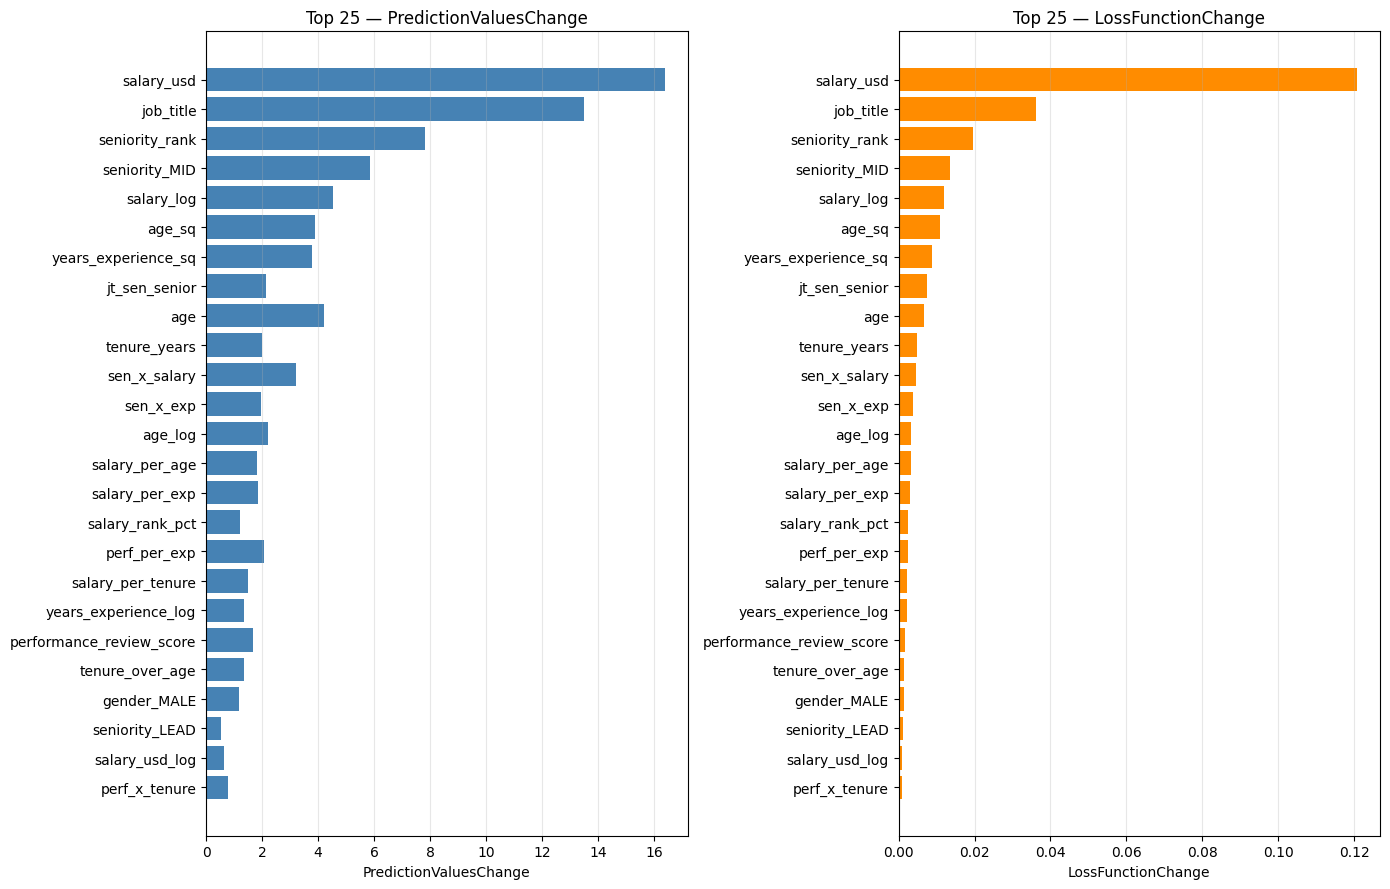


Top 15 feature interactions (CatBoost):
  salary_usd                          × salary_log                          : 4.9410
  salary_usd                          × sen_x_salary                        : 2.2225
  salary_usd                          × salary_rank_pct                     : 1.7408
  salary_usd                          × seniority_MID                       : 1.3902
  job_title                           × salary_usd                          : 1.2255
  salary_usd                          × seniority_rank                      : 1.2203
  seniority_rank                      × jt_sen_senior                       : 1.2135
  salary_usd                          × salary_per_age                      : 1.0371
  salary_usd                          × salary_per_exp                      : 1.0092
  age                                 × years_experience_sq                 : 0.9546
  years_experience_sq                 × jt_sen_senior                       : 0.9218
  salary_usd            

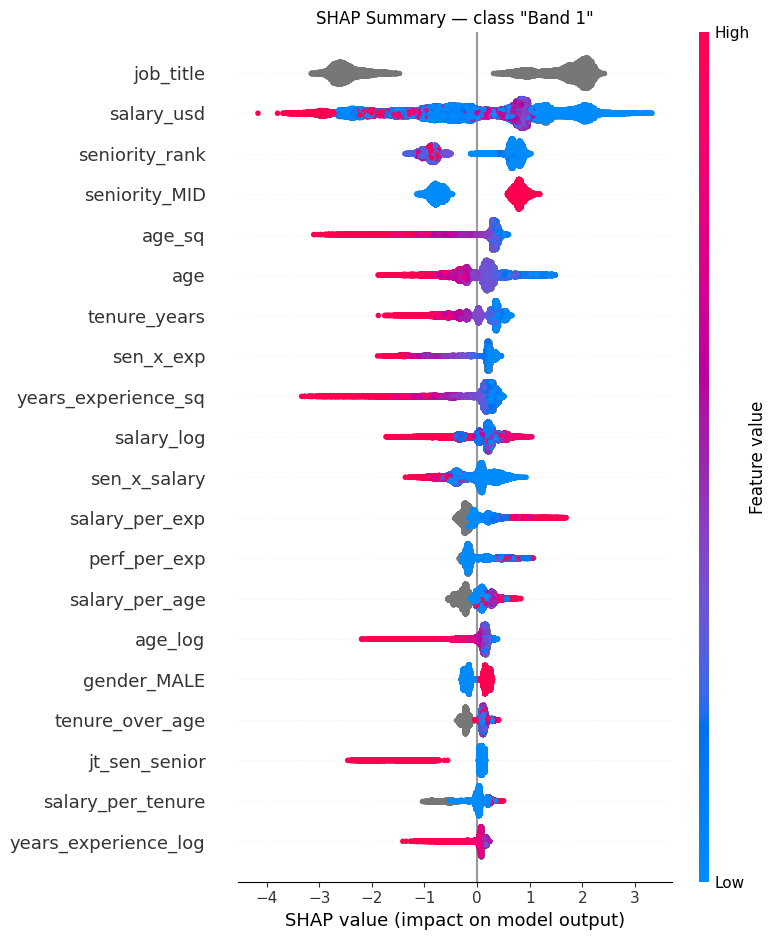

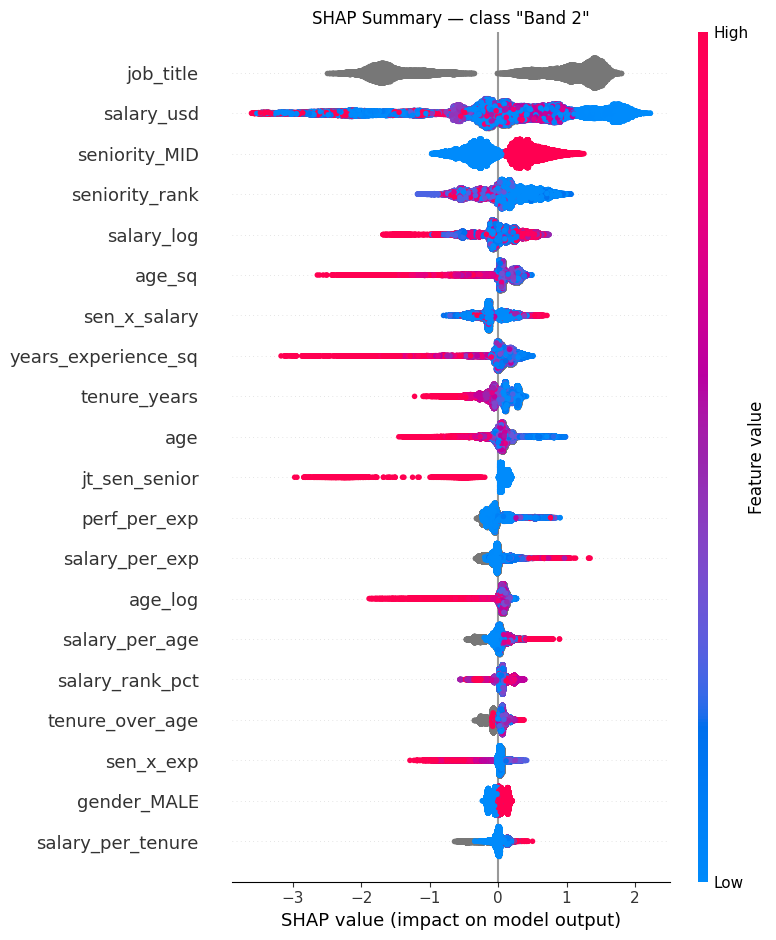

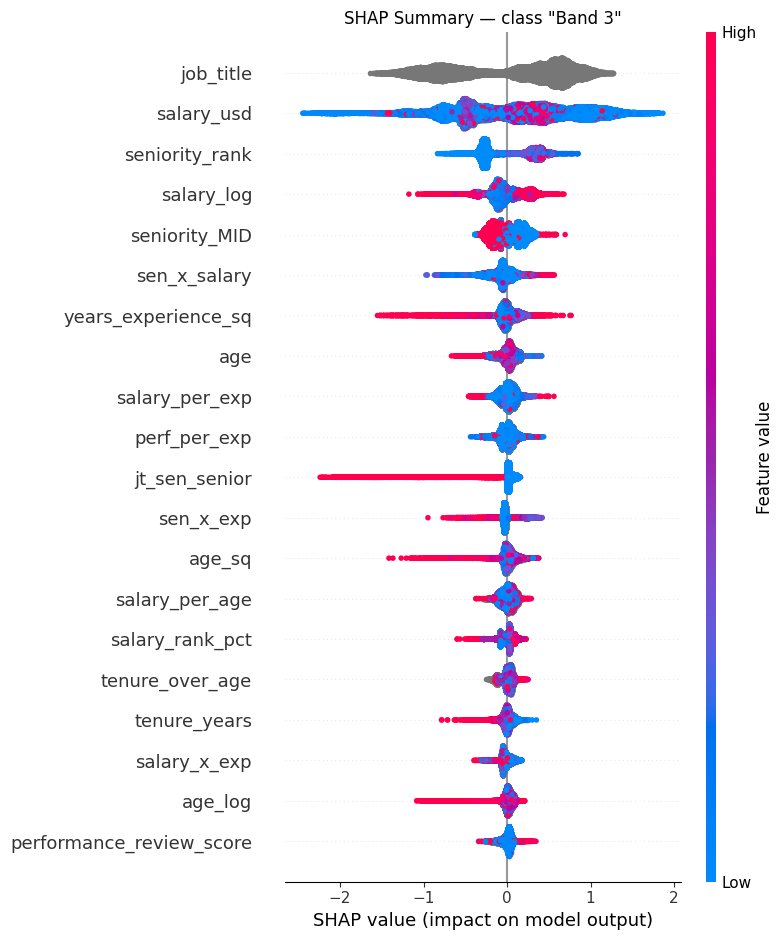

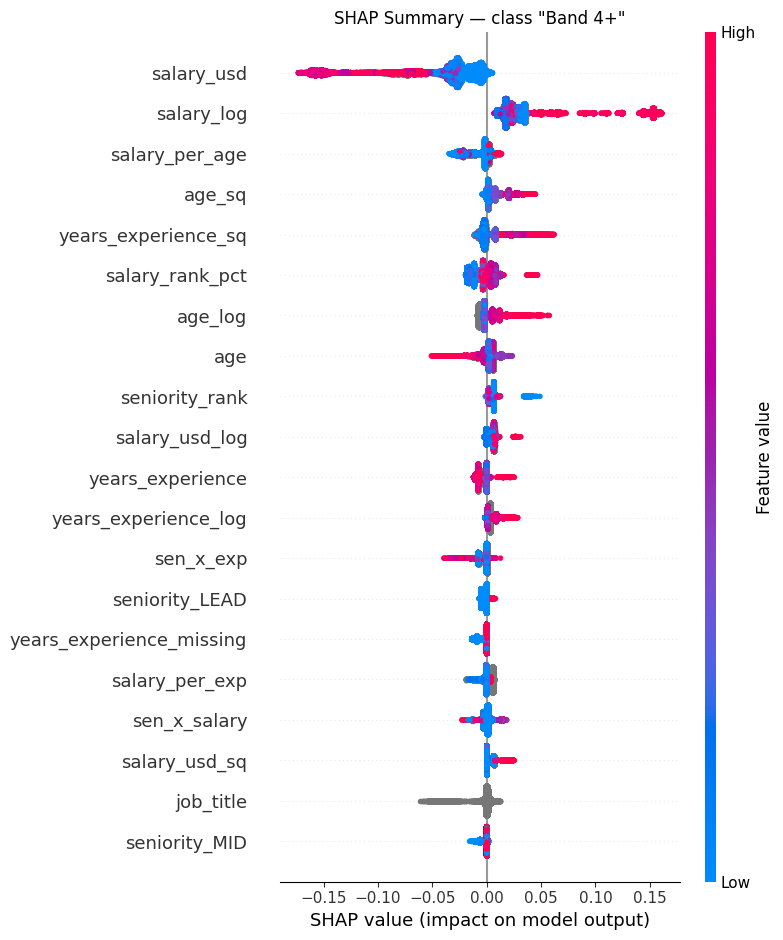


SHAP GLOBAL IMPORTANCE — Top 25
                 feature mean_abs
               job_title  0.99288
              salary_usd  0.70110
          seniority_rank  0.35443
           seniority_MID  0.33345
                  age_sq  0.19321
              salary_log  0.18632
            sen_x_salary  0.15912
                     age  0.15777
     years_experience_sq  0.15475
            tenure_years  0.15030
               sen_x_exp  0.13042
            perf_per_exp  0.11218
          salary_per_exp  0.11115
          salary_per_age  0.09959
           jt_sen_senior  0.09466
                 age_log  0.09281
         tenure_over_age  0.08001
             gender_MALE  0.07854
         salary_rank_pct  0.07010
       salary_per_tenure  0.06754
    years_experience_log  0.05997
performance_review_score  0.04989
       seniority_MANAGER  0.04309
          cat_department  0.04237
           perf_x_tenure  0.04129


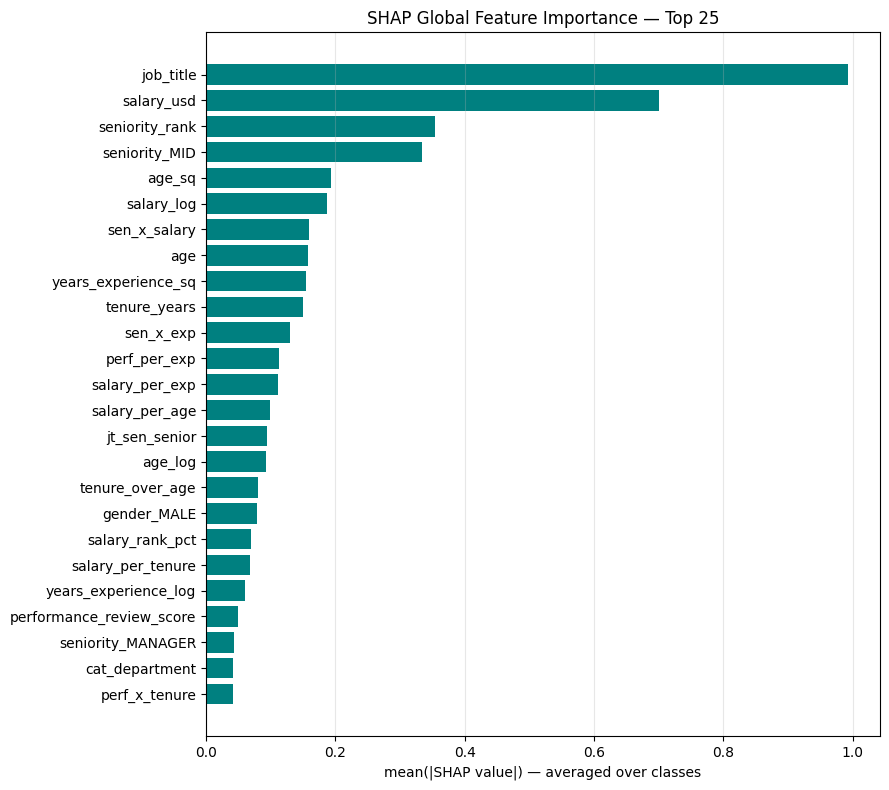


Spearman rank correlation:
  PVC   vs SHAP : +0.9974
  LFC   vs SHAP : +0.9952
  (>0.7 → konsisten; <0.5 → ada perbedaan struktur penting)

--- Sample #49348 | class=Band 1 | base=3.8921 ---
          feature                    value    shap
        job_title CUSTOMER SUCCESS MANAGER -2.6816
       salary_usd                 76825.93 -2.5487
   seniority_rank                     55.0 -0.8144
    seniority_MID                      0.0 -0.7411
        sen_x_exp                     51.0 -0.4887
       salary_log                11.249311 -0.3815
     sen_x_salary                230477.79 -0.3725
              age                     36.0 -0.3660
     tenure_years                      2.0 +0.3443
           age_sq                   1296.0 +0.2877
      gender_MALE                      1.0 +0.2274
seniority_MANAGER                      1.0 -0.2196

--- Sample #35268 | class=Band 1 | base=3.8921 ---
            feature                    value    shap
          job_title CUSTOMER SUCCESS MAN

<Figure size 2000x2000 with 0 Axes>

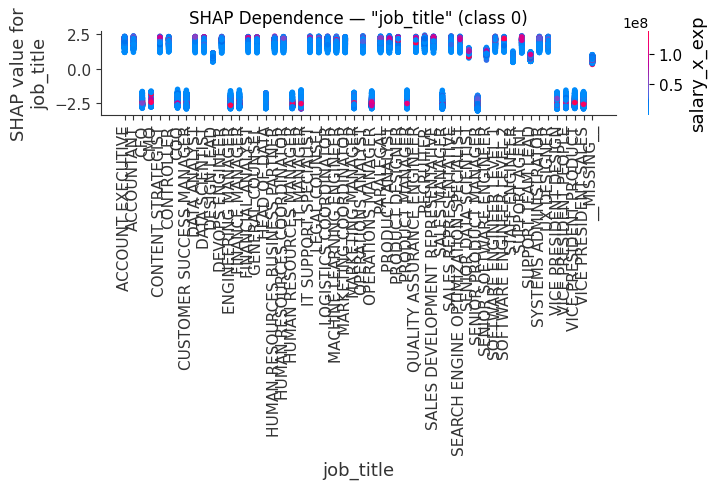


INSIGHTS

[1] Top-5 SHAP        : ['job_title', 'salary_usd', 'seniority_rank', 'seniority_MID', 'age_sq']
[2] Top-5 LFC         : ['salary_usd', 'job_title', 'seniority_rank', 'seniority_MID', 'salary_log']
[3] Top-5 PVC         : ['salary_usd', 'job_title', 'seniority_rank', 'seniority_MID', 'salary_log']

[4] Fitur robust (top-5 di SEMUA metode) : ['job_title', 'salary_usd', 'seniority_MID', 'seniority_rank']

[5] Kontribusi SHAP total:
    - kategorikal : 20.4%
    - numerik     : 79.6%

[6] Fitur pembeda antar kelas:
    class   Band 1 : [np.str_('job_title'), np.str_('salary_usd'), np.str_('seniority_rank')]
    class   Band 2 : [np.str_('job_title'), np.str_('salary_usd'), np.str_('seniority_MID')]
    class   Band 3 : [np.str_('job_title'), np.str_('salary_usd'), np.str_('seniority_rank')]
    class  Band 4+ : [np.str_('salary_usd'), np.str_('salary_log'), np.str_('salary_per_age')]

[7] Fitur dengan SHAP sangat kecil (<5% median) : 70 dari 152
    contoh: ['country_SOUTH AFRI

In [95]:
# =============================================================================
# 15. SETUP EXPLAINABILITY
# =============================================================================
import shap
from catboost import Pool
from scipy.stats import spearmanr

FEATURE_NAMES = X_final.columns.tolist()
N_FEATURES    = len(FEATURE_NAMES)

# feature_names di-pass supaya CatBoost tidak reorder & FI interaction langsung nama
train_pool = Pool(X_final, y_train, cat_features=cat_features,
                  feature_names=FEATURE_NAMES)
test_pool  = Pool(df_test_aligned, cat_features=cat_features,
                  feature_names=FEATURE_NAMES)

print(f"Explaining model on {len(X_final):,} train rows, {N_FEATURES} features, "
      f"{n_classes} classes")


# =============================================================================
# 16. FEATURE IMPORTANCE (CatBoost native — 3 types)
# =============================================================================
fi_pvc = model.get_feature_importance(train_pool, type='PredictionValuesChange')
fi_lfc = model.get_feature_importance(train_pool, type='LossFunctionChange')
fi_int = model.get_feature_importance(train_pool, type='Interaction')

fi_df = pd.DataFrame({
    'feature': FEATURE_NAMES,
    'pvc'    : fi_pvc,
    'lfc'    : fi_lfc,
}).sort_values('lfc', ascending=False).reset_index(drop=True)

fi_df['pvc_pct'] = 100 * fi_df['pvc'] / fi_df['pvc'].sum()
fi_df['rank']    = np.arange(1, len(fi_df) + 1)

print("\n" + "=" * 60)
print("FEATURE IMPORTANCE — Top 25 (by LossFunctionChange)")
print("=" * 60)
print(fi_df.head(25).to_string(
    index=False,
    formatters={'pvc': '{:.4f}'.format,
                'lfc': '{:.4f}'.format,
                'pvc_pct': '{:.2f}%'.format}
))

# ---- plot: top 25 PVC + LFC side by side ----
TOP_N = 25
top = fi_df.head(TOP_N).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 9))

axes[0].barh(top['feature'], top['pvc'], color='steelblue')
axes[0].set_xlabel('PredictionValuesChange')
axes[0].set_title(f'Top {TOP_N} — PredictionValuesChange')
axes[0].grid(axis='x', alpha=0.3)

axes[1].barh(top['feature'], top['lfc'], color='darkorange')
axes[1].set_xlabel('LossFunctionChange')
axes[1].set_title(f'Top {TOP_N} — LossFunctionChange')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()

# ---- top interactions (robust: handle index-float atau name-string) ----
def _resolve_name(x):
    """Kalau x float/int → index; kalau str → biarkan."""
    if isinstance(x, (int, float, np.integer, np.floating)):
        return FEATURE_NAMES[int(x)]
    return str(x)

fi_int_named = [
    (_resolve_name(f1), _resolve_name(f2), float(score))
    for f1, f2, score in fi_int
]

print("\nTop 15 feature interactions (CatBoost):")
for f1, f2, score in fi_int_named[:15]:
    print(f"  {f1:35s} × {f2:35s} : {score:.4f}")


# =============================================================================
# 17. SHAP VALUES (CatBoost native) — robust ke semua layout
# =============================================================================
print("\nComputing SHAP values on training set (CatBoost native)...")
shap_raw = model.get_feature_importance(train_pool, type='ShapValues')

print("=== SHAP DEBUG ===")
print(f"X_final.shape        : {X_final.shape}")
print(f"N_FEATURES           : {N_FEATURES}")
print(f"N_FEATURES + 1       : {N_FEATURES + 1}")
print(f"n_classes            : {n_classes}")
print(f"shap_raw.shape       : {shap_raw.shape}")
print(f"shap_raw.ndim        : {shap_raw.ndim}")
print("==================")

is_multiclass = n_classes > 2

# -----------------------------------------------------------------------------
# Deteksi layout secara otomatis
# -----------------------------------------------------------------------------
def _detect_and_normalize(shap_raw, n_features, n_classes):
    """
    Return (shap_values, shap_base, layout_name)
      shap_values : (n_samples, n_features, n_classes)
      shap_base   : (n_classes,) — 1D scalar per class
    """
    if shap_raw.ndim == 1:
        raise ValueError(f"SHAP 1D tidak didukung: {shap_raw.shape}")

    # ---------- BINARY ----------
    if not is_multiclass:
        if shap_raw.ndim != 2:
            raise ValueError(f"Binary SHAP harus 2D, dapat {shap_raw.shape}")
        s0, s1 = shap_raw.shape
        if s1 == n_features + 1:
            sv = shap_raw[:, :-1].reshape(s0, n_features, 1)
            base = np.array([shap_raw[0, -1]])
            return sv, base, "binary (n, F+1)"
        elif s1 == n_features:
            sv = shap_raw.reshape(s0, n_features, 1)
            return sv, np.zeros(1), "binary (n, F)"
        else:
            raise ValueError(
                f"Binary SHAP dim-2 = {s1}, tidak cocok dengan "
                f"F={n_features} atau F+1={n_features+1}"
            )

    # ---------- MULTICLASS ----------
    if shap_raw.ndim != 3:
        raise ValueError(f"Multiclass SHAP harus 3D, dapat {shap_raw.shape}")

    s0, s1, s2 = shap_raw.shape

    # Layout A: (n, F(+1), C)  — CatBoost docs klasik
    if s1 in (n_features, n_features + 1) and s2 == n_classes:
        if s1 == n_features + 1:
            sv   = shap_raw[:, :-1, :]                  # (n, F, C)
            base = shap_raw[0, -1, :]                   # (C,) — scalar per class
            return sv, base, f"multiclass (n, F+1, C) ; s1={s1}"
        else:
            sv   = shap_raw                             # (n, F, C)
            base = np.zeros(n_classes)
            return sv, base, f"multiclass (n, F, C) ; s1={s1}"

    # Layout B: (n, C, F(+1))  — versi CatBoost yang lebih baru
    if s1 == n_classes and s2 in (n_features, n_features + 1):
        if s2 == n_features + 1:
            sv   = np.transpose(shap_raw[:, :, :-1], (0, 2, 1))   # (n, F, C)
            base = shap_raw[0, :, -1]                              # (C,)
            return sv, base, f"multiclass (n, C, F+1) ; s2={s2}"
        else:
            sv   = np.transpose(shap_raw, (0, 2, 1))               # (n, F, C)
            base = np.zeros(n_classes)
            return sv, base, f"multiclass (n, C, F) ; s2={s2}"

    # ---------- tidak dikenal ----------
    raise ValueError(
        f"SHAP shape {shap_raw.shape} tidak dikenali. "
        f"Harus salah satu dari: "
        f"(n, {n_features}, {n_classes}), (n, {n_features+1}, {n_classes}), "
        f"(n, {n_classes}, {n_features}), (n, {n_classes}, {n_features+1})."
    )


shap_values, shap_base, layout = _detect_and_normalize(shap_raw, N_FEATURES, n_classes)
n_shap_classes = shap_values.shape[2]

print(f"SHAP layout detected : {layout}")
print(f"SHAP values shape    : {shap_values.shape}  (samples, features, classes)")
print(f"X_final.shape[1]     : {X_final.shape[1]}")
print(f"Base values per class: {np.round(shap_base, 4)}")

# ---------- validasi ----------
assert shap_values.shape == (len(X_final), N_FEATURES, n_shap_classes), (
    f"SHAP shape unexpected: {shap_values.shape} vs "
    f"({len(X_final)}, {N_FEATURES}, {n_shap_classes})"
)
assert shap_base.shape == (n_shap_classes,), (
    f"shap_base shape {shap_base.shape} != ({n_shap_classes},)"
)
print("✅ SHAP shape OK")

# ---------- sanity check: jumlah SHAP = prediksi - base ----------
# ambil 1 sample, bandingkan sum(shap) + base dengan prediksi model
_idx_check = 0
_sum_shap  = shap_values[_idx_check].sum(axis=0)   # (C,)
_pred_check = model.predict_proba(X_final.iloc[[_idx_check]])[0]
_diff = np.abs((_sum_shap + shap_base) - _pred_check).max()
print(f"Sanity check (sample 0) |sum(shap) + base - predict_proba|_max = {_diff:.6f}")
if _diff > 1e-3:
    print("  ⚠️  Rekonstruksi tidak persis. Mungkin CatBoost return "
          "SHAP dalam ruang raw (log-odds), bukan probabilitas.")


# =============================================================================
# 18. SHAP — GLOBAL SUMMARY (per class)
# =============================================================================
# konversi X_final ke numpy object array supaya shap tidak salah interpretasi
X_for_shap = X_final.to_numpy()

for cls_idx in range(n_shap_classes):
    cls_name = (le.classes_[cls_idx] if n_shap_classes > 1
                else le.classes_[1])

    sv = shap_values[:, :, cls_idx]
    assert sv.shape[0] == X_for_shap.shape[0], "n_samples mismatch"
    assert sv.shape[1] == X_for_shap.shape[1], (
        f"features mismatch: shap={sv.shape[1]}, X={X_for_shap.shape[1]}"
    )

    plt.figure(figsize=(10, 8))
    shap.summary_plot(
        sv,
        X_for_shap,
        feature_names=FEATURE_NAMES,
        max_display=20,
        show=False,
        plot_type='dot',
    )
    plt.title(f'SHAP Summary — class "{cls_name}"', fontsize=12)
    plt.tight_layout()
    plt.savefig(f'shap_summary_class_{cls_idx}.png', dpi=120, bbox_inches='tight')
    plt.show()


# =============================================================================
# 19. SHAP — GLOBAL BAR (mean |SHAP| aggregated over classes)
# =============================================================================
mean_abs_shap = np.abs(shap_values).mean(axis=(0, 2))   # (F,)
shap_importance = pd.DataFrame({
    'feature' : FEATURE_NAMES,
    'mean_abs': mean_abs_shap,
}).sort_values('mean_abs', ascending=False).reset_index(drop=True)

print("\n" + "=" * 60)
print("SHAP GLOBAL IMPORTANCE — Top 25")
print("=" * 60)
print(shap_importance.head(25).to_string(
    index=False,
    formatters={'mean_abs': '{:.5f}'.format}
))

top = shap_importance.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top['feature'], top['mean_abs'], color='teal')
ax.set_xlabel('mean(|SHAP value|) — averaged over classes')
ax.set_title('SHAP Global Feature Importance — Top 25')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('shap_global_importance.png', dpi=120, bbox_inches='tight')
plt.show()


# =============================================================================
# 20. SHAP — CROSS-CHECK vs NATIVE FEATURE IMPORTANCE
# =============================================================================
merged = fi_df[['feature', 'pvc', 'lfc']].merge(
    shap_importance, on='feature', how='outer'
)

rho_pvc, _ = spearmanr(merged['pvc'],      merged['mean_abs'], nan_policy='omit')
rho_lfc, _ = spearmanr(merged['lfc'],      merged['mean_abs'], nan_policy='omit')
print(f"\nSpearman rank correlation:")
print(f"  PVC   vs SHAP : {rho_pvc:+.4f}")
print(f"  LFC   vs SHAP : {rho_lfc:+.4f}")
print("  (>0.7 → konsisten; <0.5 → ada perbedaan struktur penting)")


# =============================================================================
# 21. SHAP — LOCAL EXPLANATIONS (per sample)
# =============================================================================
def explain_sample(idx, class_idx=None, top_k=12):
    """Explain satu sample dari X_final."""
    if class_idx is None:
        class_idx = int(np.abs(shap_values[idx]).sum(axis=0).argmax())

    sv = shap_values[idx, :, class_idx]
    cls_name = (le.classes_[class_idx] if n_shap_classes > 1
                else le.classes_[1])
    base_val = shap_base[class_idx] if n_shap_classes > 1 else shap_base[0]

    order = np.argsort(np.abs(sv))[::-1][:top_k]
    df = pd.DataFrame({
        'feature': [FEATURE_NAMES[i] for i in order],
        'value'  : [X_final.iloc[idx][FEATURE_NAMES[i]] for i in order],
        'shap'   : sv[order],
    })
    print(f"\n--- Sample #{idx} | class={cls_name} | base={base_val:.4f} ---")
    print(df.to_string(
        index=False,
        formatters={'value': '{!s}'.format, 'shap': '{:+.4f}'.format}
    ))


rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(X_final), size=3, replace=False)
for i in sample_idx:
    explain_sample(int(i))


# =============================================================================
# 22. SHAP — DEPENDENCE PLOT UNTUK TOP FEATURE
# =============================================================================
top_feature = shap_importance.iloc[0]['feature']
top_idx     = FEATURE_NAMES.index(top_feature)
target_cls  = int(np.abs(shap_values[:, top_idx, :]).mean(axis=0).argmax())

plt.figure(figsize=(20, 20))
shap.dependence_plot(
    top_idx,
    shap_values[:, :, target_cls],
    X_for_shap,
    feature_names=FEATURE_NAMES,
    show=False,
)
plt.title(f'SHAP Dependence — "{top_feature}" (class {target_cls})')
plt.tight_layout()
plt.savefig('shap_dependence_top.png', dpi=120, bbox_inches='tight')
plt.show()


# =============================================================================
# 23. INSIGHTS — auto-generated summary
# =============================================================================
print("\n" + "=" * 60)
print("INSIGHTS")
print("=" * 60)

top5_shap = shap_importance.head(5)['feature'].tolist()
top5_lfc  = fi_df.head(5)['feature'].tolist()
top5_pvc  = fi_df.sort_values('pvc', ascending=False).head(5)['feature'].tolist()

print(f"\n[1] Top-5 SHAP        : {top5_shap}")
print(f"[2] Top-5 LFC         : {top5_lfc}")
print(f"[3] Top-5 PVC         : {top5_pvc}")

consensus = set(top5_shap) & set(top5_lfc) & set(top5_pvc)
print(f"\n[4] Fitur robust (top-5 di SEMUA metode) : {sorted(consensus) or '(kosong)'}")

cat_imp = (shap_importance
           .assign(is_cat=lambda d: d['feature'].isin(cat_features))
           .groupby('is_cat')['mean_abs'].sum())
total_imp = cat_imp.sum() if cat_imp.sum() > 0 else 1.0
print(f"\n[5] Kontribusi SHAP total:")
print(f"    - kategorikal : {100 * cat_imp.get(True,  0) / total_imp:.1f}%")
print(f"    - numerik     : {100 * cat_imp.get(False, 0) / total_imp:.1f}%")

print(f"\n[6] Fitur pembeda antar kelas:")
for cls_idx in range(n_shap_classes):
    cls_name = (le.classes_[cls_idx] if n_shap_classes > 1 else le.classes_[1])
    per_feat = np.abs(shap_values[:, :, cls_idx]).mean(axis=0)
    top3 = np.array(FEATURE_NAMES)[np.argsort(per_feat)[::-1][:3]]
    print(f"    class {cls_name:>8s} : {list(top3)}")

low_imp = shap_importance[
    shap_importance['mean_abs'] < shap_importance['mean_abs'].median() * 0.05
]
print(f"\n[7] Fitur dengan SHAP sangat kecil (<5% median) : "
      f"{len(low_imp)} dari {N_FEATURES}")
if len(low_imp) > 0:
    print(f"    contoh: {low_imp['feature'].head(10).tolist()}")
    print("    → kandidat untuk drop di iterasi berikutnya")

top_interactions = fi_int_named[:5]
print(f"\n[8] Interaksi terkuat (CatBoost):")
for f1, f2, score in top_interactions:
    print(f"    {f1:30s} × {f2:30s} : {score:.4f}")
print("    → pasangan ini layak dibuat fitur eksplisit kalau belum ada")


# =============================================================================
# 24. SAVE EXPLAINABILITY ARTIFACTS
# =============================================================================
fi_df.to_csv('explain_feature_importance.csv', index=False)
shap_importance.to_csv('explain_shap_global.csv', index=False)
pd.DataFrame(fi_int_named, columns=['feature_1', 'feature_2', 'score']).to_csv(
    'explain_interactions.csv', index=False
)

joblib.dump({
    'feature_names'  : FEATURE_NAMES,
    'cat_features'   : list(cat_features),
    'n_shap_classes' : n_shap_classes,
    'shap_base'      : shap_base,
    'shap_importance': shap_importance,
    'fi_df'          : fi_df,
    'fi_interactions': fi_int_named,
}, 'explain_artifacts.pkl')

print("\n✅ Explainability artifacts disimpan:")
print("   - explain_feature_importance.csv")
print("   - explain_shap_global.csv")
print("   - explain_interactions.csv")
print("   - explain_artifacts.pkl")
print("   - shap_summary_class_*.png")
print("   - shap_global_importance.png")
print("   - shap_dependence_top.png")
print("   - feature_importance.png")

In [96]:
df_test_aligned = df_test[train_columns].copy()

for col in cat_features:
    df_test_aligned[col] = (
        df_test_aligned[col]
        .fillna('__MISSING__')
        .astype(str)
    )
    known = set(train_categories[col])
    df_test_aligned.loc[~df_test_aligned[col].isin(known), col] = '__MISSING__'

num_cols = [c for c in train_columns if c not in cat_features]
df_test_aligned[num_cols] = df_test_aligned[num_cols].apply(pd.to_numeric, errors='coerce')

y_proba    = model.predict_proba(df_test_aligned)
y_pred_int = (y_proba.argmax(axis=1) if y_proba.shape[1] > 1
              else (y_proba.ravel() >= 0.5).astype(int))
y_test     = le.inverse_transform(y_pred_int)

# Submission

**DILARANG MENGUBAH CODE!!!!!!!!!!!**

**Pastikan memiliki variabel berikut:**
`X_test` (hasil preprocessing dari `df_test`, **jumlah dan urutan barisnya harus sama** dengan `df_test`)

In [98]:
id = df_test.index.tolist()

submission_df = pd.DataFrame({'employee_id': id, 'pay_band': y_test})

assert len(submission_df) == len(df_test), 'Jumlah baris submission harus sama dengan test.csv!'
assert set(submission_df['pay_band']) <= {'Band 1', 'Band 2', 'Band 3', 'Band 4+'}, \
    'Isi pay_band harus label asli: Band 1 / Band 2 / Band 3 / Band 4+'

submission_df.to_csv('submission.csv', index=False)
submission_df.head()

,employee_id,pay_band
0,EMP-196598,Band 1
1,EMP-156920,Band 3
2,EMP-161973,Band 2
3,EMP-195108,Band 2
4,EMP-111307,Band 2
